<a href="https://colab.research.google.com/github/mrcastilla8/Labs-Mineria/blob/master/Semana%2014/G2_Lab_Electricidad.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Laboratorio integral de electricidad: detección de fraude

El estudio aborda la detección de fraude como una clasificación binaria por consumidor: `FLAG=1` identifica fraude y `FLAG=0` su ausencia. `CONS_NO` se conservó como identificador y quedó excluido de los predictores. El conjunto analizado reunió **42.372 consumidores** y **1.034 fechas**.

El informe presenta la ejecución guardada en modo `COMPLETO`, que alcanzó la evaluación final sobre TEST. La metodología, los resultados y sus limitaciones se describen en los capítulos siguientes.

## 0. Diseño experimental y reproducibilidad

La ejecución completa utilizó todos los consumidores, semilla `111` y una partición estratificada por consumidor: 56 % TRAIN, 14 % VALID y 30 % TEST. TRAIN y VALID forman el conjunto de desarrollo; TEST permaneció fuera de la selección y se evaluó una sola vez tras fijar la configuración.

La métrica primaria fue Average Precision (PR-AUC) en VALID; los desempates se definieron por recall de fraude, F1 de fraude y orden alfabético. Se reportan además ROC-AUC, precision, recall, F1, accuracy y matriz de confusión.

El imputador iterativo, los escaladores, ICA, PLS y Autoencoder se ajustaron con TRAIN y se aplicaron a VALID/TEST sin reajuste. SMOTE y ADASYN se aplicaron solo al conjunto de entrenamiento de cada etapa. `CONS_NO` y `FLAG` no se utilizaron como predictores. El modo `RAPIDO` sirve para comprobaciones técnicas; las conclusiones empíricas de este informe proceden de `COMPLETO`.

In [1]:
# 0.1. Dependencias Colab: instalar únicamente las que faltan
import importlib.util, subprocess, sys
PAQUETES = {
    'numpy':'numpy', 'pandas':'pandas', 'scipy':'scipy',
    'sklearn':'scikit-learn', 'imblearn':'imbalanced-learn',
    'tqdm':'tqdm', 'matplotlib':'matplotlib',
    'xgboost':'xgboost', 'lightgbm':'lightgbm',
    'pyarrow':'pyarrow', 'joblib':'joblib',
    'tensorflow':'tensorflow',
}
faltantes = [paquete for modulo, paquete in PAQUETES.items()
             if importlib.util.find_spec(modulo) is None]
if faltantes:
    print('Instalando paquetes ausentes:', ', '.join(faltantes), flush=True)
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *faltantes])
    importlib.invalidate_caches()
else:
    print('Dependencias principales presentes; no se reinstala innecesariamente.')
print('Nota: si Colab indica reiniciar sesión tras actualizar paquetes, reiníciala antes de continuar.')

Dependencias principales presentes; no se reinstala innecesariamente.
Nota: si Colab indica reiniciar sesión tras actualizar paquetes, reiníciala antes de continuar.


In [2]:
# 0.2. Importaciones, límites de hilos y semilla global
import os, gc, json, time, math, random, hashlib, warnings, sys
from pathlib import Path
from dataclasses import dataclass, asdict
from contextlib import contextmanager
from datetime import datetime, timezone
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
from sklearn.model_selection import train_test_split
from sklearn.metrics import (average_precision_score, roc_auc_score,
    precision_score, recall_score, f1_score, accuracy_score,
    confusion_matrix, ConfusionMatrixDisplay, PrecisionRecallDisplay)
from sklearn.preprocessing import StandardScaler
from sklearn.base import clone

SEED = 111
random.seed(SEED)
np.random.seed(SEED)
os.environ['PYTHONHASHSEED'] = str(SEED)
os.environ.setdefault('OMP_NUM_THREADS', '2')
os.environ.setdefault('OPENBLAS_NUM_THREADS', '2')
os.environ.setdefault('MKL_NUM_THREADS', '2')
try:
    import tensorflow as tf
    tf.keras.utils.set_random_seed(SEED)
    try: tf.config.experimental.enable_op_determinism()
    except Exception: pass
    print('TensorFlow', tf.__version__, '| GPU:', [d.name for d in tf.config.list_physical_devices('GPU')])
except Exception as e:
    raise RuntimeError('TensorFlow es necesario para el Autoencoder: '+str(e))
print('Python', sys.version.split()[0], '| NumPy', np.__version__, '| pandas',pd.__version__)

TensorFlow 2.21.0 | GPU: []
Python 3.13.18 | NumPy 2.4.6 | pandas 2.2.3


In [3]:
# 0.3. ÚNICA celda de parámetros editables por el equipo
@dataclass(frozen=True)
class Config:
    modo: str = 'COMPLETO'
    dataset: str = os.environ.get('ELECTRICIDAD_DATASET','').strip()
    raiz: str = os.environ.get('ELECTRICIDAD_OUTPUT_DIR',
        str(Path('/content/laboratorio_electricidad') if Path('/content').is_dir()
            else Path.cwd()/'resultados_electricidad'))
    semilla: int = 111
    test_size: float = 0.30
    valid_fraction_in_dev: float = 0.20
    max_consumidores_rapido: int = 3000
    chunk_filas: int = 512
    n_jobs: int = 2
    aplicar_cache_resumen: bool = True
    estrategia_sintetica: float = 0.8
    k_vecinos_balance: int = 5
    umbral_clase: float = 0.5
    evaluacion_iterativa_legado_en_rapido: bool = False
    epochs_rapido: int = 2
    epochs_completo: int = 20
    batch_ae: int = 256
    paciencia_ae: int = 4
    n_componentes_ica: int = 10
    n_componentes_pls: int = 8

CFG = Config()
if CFG.modo not in {'RAPIDO','COMPLETO'}: raise ValueError('ELECTRICIDAD_MODO debe ser RAPIDO o COMPLETO')
if CFG.semilla != 111: raise ValueError('El protocolo de Semana 14 fija la semilla en 111')
if CFG.max_consumidores_rapido > 3000: raise ValueError('RAPIDO admite como máximo 3000 consumidores')
if not 0 < CFG.test_size < 1 or not 0 < CFG.valid_fraction_in_dev < 1:
    raise ValueError('Fracciones de partición fuera de (0,1)')
RUTA = Path(CFG.raiz).expanduser().resolve()
for subdir in ['cache','figuras','metricas','modelos','registro']:
    (RUTA/subdir).mkdir(parents=True,exist_ok=True)
print('MODO:',CFG.modo,'| salida:',RUTA)
print('ATENCIÓN: RAPIDO sirve para comprobar código, NO como evidencia final.')


MODO: COMPLETO | salida: /content/laboratorio_electricidad
ATENCIÓN: RAPIDO sirve para comprobar código, NO como evidencia final.


In [4]:
# 0.4. Registro de tiempos, memoria, errores y progreso visible en Colab
import logging, tempfile
from IPython.display import display
logging.basicConfig(level=logging.INFO,format='%(asctime)s | %(levelname)s | %(message)s',force=True)
LOG = logging.getLogger('electricidad')
REGISTRO = []

@contextmanager
def etapa(nombre):
    t0=time.perf_counter()
    LOG.info('INICIO: %s',nombre)
    try:
        yield
    except Exception as exc:
        dt=time.perf_counter()-t0
        REGISTRO.append({'etapa':nombre,'estado':'ERROR','segundos':round(dt,2),'detalle':str(exc)[:300]})
        LOG.exception('ERROR en %s (%.1f s)',nombre,dt)
        try: exportar_csv(pd.DataFrame(REGISTRO),RUTA/'registro'/'etapas_y_tiempos.csv')
        except Exception as log_exc: LOG.error('No se pudo persistir el registro de error: %s',log_exc)
        raise
    else:
        dt=time.perf_counter()-t0
        REGISTRO.append({'etapa':nombre,'estado':'PASS','segundos':round(dt,2),'detalle':''})
        LOG.info('FIN: %s (%.1f s)',nombre,dt)

def resumen_progreso():
    display(pd.DataFrame(REGISTRO).tail(20))

def memoria_objetos(*objetos):
    total=sum(getattr(obj,'nbytes',0) for obj in objetos if obj is not None)
    print(f'Memoria de matrices indicadas: {total/(1024**2):,.1f} MiB',flush=True)

def exportar_json(datos,ruta):
    ruta=Path(ruta);ruta.parent.mkdir(parents=True,exist_ok=True)
    temporal=ruta.with_name(ruta.name+'.tmp')
    with temporal.open('w',encoding='utf-8') as f: json.dump(datos,f,ensure_ascii=False,indent=2,allow_nan=False,default=str)
    temporal.replace(ruta)

def exportar_csv(tabla,ruta):
    ruta=Path(ruta);ruta.parent.mkdir(parents=True,exist_ok=True)
    temporal=ruta.with_name(ruta.name+'.tmp')
    tabla.to_csv(temporal,index=False)
    temporal.replace(ruta)

RUN_ID=datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%SZ')
print('Identificador de ejecución:',RUN_ID)


Identificador de ejecución: 20261124T215230Z


### 0.5. Datos de entrada

La entrada contiene `CONS_NO`, `FLAG` y 1.034 columnas de fechas de consumo. Antes de la partición se validaron IDs, etiquetas, calendario y tipos numéricos. El dataset no se incorpora por su tamaño; las métricas y figuras incrustadas proceden de las salidas guardadas de Colab.


In [5]:
# 0.5.1. Ubicar dataset, verificar esquema y cargar optimizando RAM

def localizar_dataset(cfg=CFG):
    candidatos=[Path(cfg.dataset).expanduser()] if cfg.dataset.strip() else []
    candidatos += [Path(os.environ.get('ELECTRICIDAD_DATASET','/content/data.csv')),
                   Path('/content/drive/MyDrive/Laboratorio_Electricidad/data.csv'),Path('data.csv')]
    for p in candidatos:
        if p.is_file(): return p.resolve()
    # En Colab, intentar montar Drive solo si está disponible. Fuera de Colab no falla por ello.
    if any(str(p).startswith('/content/drive') for p in candidatos):
        try:
            from google.colab import drive
            drive.mount('/content/drive',force_remount=False)
            p=Path('/content/drive/MyDrive/Laboratorio_Electricidad/data.csv')
            if p.is_file(): return p.resolve()
        except Exception as exc:
            LOG.warning('No se pudo montar Google Drive: %s',str(exc)[:250])
    raise FileNotFoundError('Falta el dataset. Usa ELECTRICIDAD_DATASET/CFG.dataset, data.csv junto al notebook o /content/data.csv. En Colab puedes montar Drive con drive.mount("/content/drive").')

def cargar_electricidad(path):
    headers=pd.read_csv(path,nrows=0).columns.tolist()
    if len(headers)!=len(set(headers)): raise ValueError('El CSV contiene encabezados duplicados')
    if not {'CONS_NO','FLAG'}.issubset(headers):
        raise ValueError('El CSV debe contener CONS_NO y FLAG; columnas encontradas: '+str(headers[:8]))
    fechas=[c for c in headers if c not in {'CONS_NO','FLAG'}]
    dt=pd.to_datetime(pd.Index(fechas),format='%Y/%m/%d',errors='coerce')
    if len(fechas)<32 or dt.isna().any() or dt.duplicated().any():
        raise ValueError('Se requieren al menos 32 columnas-fecha únicas válidas (YYYY/MM/DD)')
    fechas_ordenadas=[c for _,c in sorted(zip(dt,fechas))]
    dtype={'CONS_NO':'string','FLAG':'Int8',**{c:'float32' for c in fechas}}
    df=pd.read_csv(path,dtype=dtype,na_values=['?','NA','NaN','null','NULL',''])
    if df.empty: raise ValueError('El CSV no contiene consumidores')
    if df['CONS_NO'].isna().any() or df['CONS_NO'].duplicated().any():
        raise ValueError('CONS_NO requiere IDs únicos no nulos para garantizar partición por consumidor')
    if df['FLAG'].isna().any() or not set(df['FLAG'].unique()).issubset({0,1}) or df['FLAG'].nunique()!=2:
        raise ValueError('FLAG debe contener ambas clases 0 y 1, sin nulos')
    y=df['FLAG'].to_numpy(dtype=np.int8,na_value=-1)
    ids=df['CONS_NO'].astype(str).to_numpy()
    X=df[fechas_ordenadas].to_numpy(dtype=np.float32,copy=True)
    fechas_dt=pd.to_datetime(fechas_ordenadas,format='%Y/%m/%d')
    t_dias=(fechas_dt-fechas_dt.min()).days.to_numpy(dtype=np.float64)
    del df;gc.collect()
    if not np.isfinite(X[~np.isnan(X)]).all(): raise ValueError('Consumos contienen valores no finitos distintos de NaN')
    return X,y,ids,t_dias,fechas_ordenadas

def identidad_archivo(path,bloque=1024*1024):
    h=hashlib.sha256()
    with open(path,'rb') as f:
        for b in iter(lambda:f.read(bloque),b''): h.update(b)
    return h.hexdigest()

with etapa('Carga y validación de data.csv'):
    DATASET_PATH=localizar_dataset()
    X_raw,y_raw,ids_raw,t_dias,fechas= cargar_electricidad(DATASET_PATH)
    DATASET_KEY=identidad_archivo(DATASET_PATH)
    print('Dataset:',DATASET_PATH.name,'| SHA256:',DATASET_KEY[:12],'| consumidores:',len(y_raw),'| fechas:',len(fechas))
    print('Clases:',dict(zip(*np.unique(y_raw,return_counts=True))))
    print('NaN:',int(np.isnan(X_raw).sum()),'| negativos:',int((X_raw<0).sum()))
    memoria_objetos(X_raw)


2026-11-24 21:52:30,974 | INFO | INICIO: Carga y validación de data.csv


Dataset: data.csv | SHA256: 99f8fd315626 | consumidores: 42372 | fechas: 1034
Clases: {np.int8(0): np.int64(38757), np.int8(1): np.int64(3615)}
NaN: 11233528 | negativos: 0
Memoria de matrices indicadas: 167.1 MiB


2026-11-24 21:52:59,082 | INFO | FIN: Carga y validación de data.csv (28.1 s)


In [6]:
# 0.6. Un único split estratificado y SIN utilizar los ID como features
def crear_particiones(y,modo='RAPIDO',semilla=111,max_rapido=3000,test_size=.30,valid_fraction=.20):
    y=np.asarray(y)
    if y.ndim!=1 or set(np.unique(y))!={0,1}: raise ValueError('y debe ser vector binario con ambas clases')
    conteos=np.bincount(y.astype(np.int8),minlength=2)
    if conteos.min()<3: raise ValueError('Se requieren al menos 3 consumidores por clase')
    indices=np.arange(len(y))
    dev,test=train_test_split(indices,test_size=test_size,stratify=y,random_state=semilla)
    train,valid=train_test_split(dev,test_size=valid_fraction,stratify=y[dev],random_state=semilla)
    if modo=='RAPIDO' and len(y)>max_rapido:
        n=max_rapido
        tamaños=np.rint(np.array([.56,.14,.30])*n).astype(int)
        tamaños[0]+=n-int(tamaños.sum())
        def submuestrear(ix,k):
            if len(ix)<=k:return ix
            if min(np.bincount(y[ix].astype(np.int8),minlength=2))<2*k/len(ix):
                # Delegar la comprobación exacta a sklearn para dar un error explícito.
                pass
            sub,_=train_test_split(ix,train_size=k,stratify=y[ix],random_state=semilla)
            return np.sort(sub)
        train,valid,test=(submuestrear(train,int(t)) for train,t in zip((train,valid,test),tamaños))
    if len(set(np.concatenate([train,valid,test]).tolist()))!=len(train)+len(valid)+len(test):
        raise AssertionError('Particiones con solapamiento')
    for nombre,ix in [('TRAIN',train),('VALID',valid),('TEST',test)]:
        if len(ix)==0 or set(np.unique(y[ix]))!={0,1}: raise ValueError(f'{nombre} no contiene ambas clases')
    return np.sort(train),np.sort(valid),np.sort(test)

with etapa('División reproducible 56/14/30'):
    idx_train,idx_valid,idx_test=crear_particiones(y_raw,CFG.modo,CFG.semilla,CFG.max_consumidores_rapido,CFG.test_size,CFG.valid_fraction_in_dev)
    X_train_raw=X_raw[idx_train].copy(); y_train=y_raw[idx_train].copy()
    X_valid_raw=X_raw[idx_valid].copy(); y_valid=y_raw[idx_valid].copy()
    X_test_raw=X_raw[idx_test].copy(); y_test=y_raw[idx_test].copy()
    for n,y in [('TRAIN',y_train),('VALID',y_valid)]:
        print(f'{n:5s}: n={len(y):6d}, fraude={int(y.sum()):5d}, ratio={np.mean(y):.2%}')
    print(f'TEST : n={len(y_test):6d} (etiquetas reservadas hasta evaluación final)')
    del X_raw;gc.collect()


2026-11-24 21:52:59,116 | INFO | INICIO: División reproducible 56/14/30


TRAIN: n= 23728, fraude= 2024, ratio=8.53%
VALID: n=  5932, fraude=  506, ratio=8.53%
TEST : n= 12712 (etiquetas reservadas hasta evaluación final)


2026-11-24 21:53:00,090 | INFO | FIN: División reproducible 56/14/30 (1.0 s)


### 0.7. Integridad de los datos y particiones

Se verificaron IDs únicos, separación de consumidores entre particiones, fechas crecientes, presencia de ambas clases y tipo `float32` de las matrices. La división 56/14/30 produjo 23.728 consumidores en TRAIN, 5.932 en VALID y 12.712 en TEST. TRAIN y VALID conservaron una proporción de fraude de 8,53 %; las etiquetas de TEST se reservaron hasta la evaluación final.

In [7]:
# Pruebas de integridad y funciones comunes
assert np.all(np.diff(t_dias)>0),'Fechas no crecientes'
assert all(x.dtype==np.float32 for x in (X_train_raw,X_valid_raw,X_test_raw))
assert set(np.unique(y_train))==set(np.unique(y_valid))==set(np.unique(y_test))=={0,1}
assert X_train_raw.shape[1]==X_valid_raw.shape[1]==X_test_raw.shape[1]==len(t_dias)
assert not (set(idx_train)&set(idx_valid) or set(idx_train)&set(idx_test) or set(idx_valid)&set(idx_test))
assert len(set(ids_raw[idx_train])&set(ids_raw[idx_valid]))==0
assert len(set(ids_raw[idx_train])&set(ids_raw[idx_test]))==0
assert len(set(ids_raw[idx_valid])&set(ids_raw[idx_test]))==0
# Fixture técnico exclusivamente para comprobar proporciones, estratificación y orden.
_yfixture=np.tile(np.array([0,1],dtype=np.int8),2000)
_a,_b,_c=crear_particiones(_yfixture,'RAPIDO',111,3000)
assert (len(_a),len(_b),len(_c))==(1680,420,900)
_d,_e,_f=crear_particiones(_yfixture,'COMPLETO',111,3000)
assert (len(_d),len(_e),len(_f))==(2240,560,1200)
assert not (set(_a)&set(_b) or set(_a)&set(_c) or set(_b)&set(_c))
assert max(len(np.unique(_yfixture[x])) for x in (_a,_b,_c))==2
# Exportaciones JSON/CSV legibles, sin conservar archivos de fixture.
with tempfile.TemporaryDirectory() as _td:
    _jp=Path(_td)/'sub'/'fixture.json';_cp=Path(_td)/'sub'/'fixture.csv'
    exportar_json({'fixture_tecnico':True,'valor':1},_jp)
    exportar_csv(pd.DataFrame([{'fixture_tecnico':True,'valor':1}]),_cp)
    assert json.loads(_jp.read_text(encoding='utf-8'))['fixture_tecnico'] is True
    assert pd.read_csv(_cp).iloc[0]['valor']==1
# Loader técnico: fechas desordenadas se ordenan cronológicamente; ID nunca es predictor.
with tempfile.TemporaryDirectory() as _td:
    _d0=pd.date_range('2011-01-01',periods=32,freq='D')
    _cols=[d.strftime('%Y/%m/%d') for d in _d0[::-1]]
    _fixture=pd.DataFrame({'CONS_NO':[f'id{i}' for i in range(12)],'FLAG':[0,1]*6,
        **{col:np.arange(12,dtype=np.float32)+j for j,col in enumerate(_cols)}})
    _csv=Path(_td)/'fixture_tecnico.csv';_fixture.to_csv(_csv,index=False)
    _xx,_yy,_ids,_tt,_dates=cargar_electricidad(_csv)
    assert _xx.shape==(12,32) and _xx.dtype==np.float32 and set(_yy)=={0,1}
    assert _dates==sorted(_dates) and np.all(np.diff(_tt)>0)
    assert np.array_equal(_ids,np.array([f'id{i}' for i in range(12)]))
    _fixture.loc[1,'CONS_NO']=_fixture.loc[0,'CONS_NO'];_fixture.to_csv(_csv,index=False)
    try:cargar_electricidad(_csv)
    except ValueError as _exc:assert 'CONS_NO' in str(_exc)
    else:raise AssertionError('El loader aceptó IDs duplicados')
# La etapa registra un error real y lo vuelve a propagar.
_nreg=len(REGISTRO)
try:
    with etapa('fixture_tecnico_error'):
        raise RuntimeError('error_fixture')
except RuntimeError: pass
else: raise AssertionError('etapa no propagó el error')
assert REGISTRO[-1]['estado']=='ERROR' and len(REGISTRO)==_nreg+1
print('PASS: integridad de particiones, estratificación, exportaciones y registro de errores (fixtures técnicos).')


2026-11-24 21:53:00,700 | INFO | INICIO: fixture_tecnico_error
2026-11-24 21:53:00,702 | ERROR | ERROR en fixture_tecnico_error (0.0 s)
Traceback (most recent call last):
  File "/tmp/ipykernel_11007/2220568778.py", line 13, in etapa
    yield
  File "/tmp/ipykernel_11007/3749845202.py", line 44, in <cell line: 0>
    raise RuntimeError('error_fixture')
RuntimeError: error_fixture


PASS: integridad de particiones, estratificación, exportaciones y registro de errores (fixtures técnicos).


## 1. Análisis exploratorio

El análisis exploratorio se realizó sobre TRAIN+VALID, con TEST excluido de la exploración previa a la selección. Se examinaron la prevalencia de clases, los valores faltantes, el calendario y la distribución del consumo.

Las tablas resumen las tasas de faltantes y la composición de clases; las figuras muestran patrones temporales y ejemplos de series muestreadas. Estas visualizaciones describen los datos observados y no permiten inferir causas de las diferencias entre clases.

In [8]:
def validar_calendario_eda(fechas_calendario, dias_desde_inicio):
    calendario=pd.DatetimeIndex(fechas_calendario)
    dias=np.asarray(dias_desde_inicio,dtype=np.float64)
    if calendario.ndim!=1 or len(calendario)!=len(dias):
        raise ValueError('El calendario de fechas debe coincidir con la longitud de t_dias.')
    if len(calendario)>1 and not np.all(np.diff(calendario.asi8)>0):
        raise ValueError('Las fechas del calendario deben ser estrictamente crecientes.')
    transcurridos=(calendario-calendario[0]).days.to_numpy(dtype=np.float64) if len(calendario) else np.array([],dtype=np.float64)
    if not np.array_equal(transcurridos,dias):
        raise ValueError('Las diferencias de calendario en días no coinciden con t_dias.')
    return calendario

def muestrear_matrices_proporcional(matrices, semilla, max_total=200_000):
    # Muestrea celdas sin concatenar las matrices y reparte cupos por tamaño.
    matrices=[np.asarray(m) for m in matrices]
    tamanos=np.asarray([m.size for m in matrices],dtype=np.int64)
    total=int(tamanos.sum())
    limite=min(max(0,int(max_total)),total)
    cupos=np.zeros(len(matrices),dtype=np.int64)
    if total and limite:
        exactos=limite*tamanos.astype(np.float64)/total
        cupos=np.floor(exactos).astype(np.int64)
        resto=limite-int(cupos.sum())
        orden=sorted(range(len(matrices)),key=lambda i:(-(exactos[i]-cupos[i]),i))
        for i in orden:
            if resto<=0: break
            if cupos[i]<tamanos[i]: cupos[i]+=1; resto-=1
    rng=np.random.default_rng(semilla)
    muestras=[]
    for matriz,cupo in zip(matrices,cupos):
        plano=matriz.reshape(-1)
        if cupo==plano.size: muestras.append(plano.copy())
        elif cupo: muestras.append(plano[rng.choice(plano.size,size=int(cupo),replace=False)])
        else: muestras.append(np.array([],dtype=matriz.dtype))
    return muestras

with etapa('EDA: distribución y calidad'):
    fechas_calendario = pd.to_datetime(fechas, format='%Y/%m/%d', errors='raise')
    fechas_calendario = validar_calendario_eda(fechas_calendario, t_dias)
    n = len(y_train)+len(y_valid); p = X_train_raw.shape[1]
    if X_valid_raw.shape[1] != p or p != len(t_dias) or p != len(fechas_calendario): raise ValueError('Matriz y calendario incompatibles.')
    y_eda = np.concatenate((y_train,y_valid))
    tabla_clases = pd.Series(y_eda,name='FLAG').value_counts().reindex([0,1],fill_value=0).rename_axis('FLAG').reset_index(name='consumidores')
    tabla_clases['denominador']=n; tabla_clases['porcentaje']=(100*tabla_clases.consumidores/max(n,1)).round(2)
    tabla_clases['registros_consumidor_fecha']=tabla_clases.consumidores*p
    print(f'EDA TRAIN+VALID: {n:,} consumidores, {p:,} fechas, {n*p:,} registros; TEST excluido.'); display(tabla_clases)
    nan_fecha=np.isnan(X_train_raw).sum(axis=0)+np.isnan(X_valid_raw).sum(axis=0)
    nan_cli=np.r_[np.isnan(X_train_raw).sum(axis=1),np.isnan(X_valid_raw).sum(axis=1)]
    faltantes_fecha=pd.DataFrame({'fecha':fechas_calendario,'faltantes':nan_fecha,'denominador':n,'porcentaje':(100*nan_fecha/max(n,1)).round(3)})
    faltantes_consumidor=pd.DataFrame({'FLAG':y_eda,'faltantes':nan_cli,'denominador':p,'porcentaje':(100*nan_cli/max(p,1)).round(3)})
    faltantes_clase=faltantes_consumidor.groupby('FLAG',as_index=False).agg(consumidores=('faltantes','size'),celdas_faltantes=('faltantes','sum'),faltantes_promedio_pct=('porcentaje','mean'))
    total=n*p; nn=int(nan_fecha.sum()); ceros=int(np.count_nonzero(X_train_raw==0)+np.count_nonzero(X_valid_raw==0)); neg=int(np.count_nonzero(X_train_raw<0)+np.count_nonzero(X_valid_raw<0))
    muestras=muestrear_matrices_proporcional((X_train_raw,X_valid_raw),CFG.semilla,max_total=200_000)
    finitos=np.concatenate([m[np.isfinite(m)] for m in muestras if m.size]) if any(m.size for m in muestras) else np.array([],dtype=np.float32)
    q1,med,q3=np.quantile(finitos,[.25,.5,.75]) if finitos.size else (np.nan,)*3
    limite_inferior=q1-1.5*(q3-q1) if finitos.size else np.nan
    limite_superior=q3+1.5*(q3-q1) if finitos.size else np.nan
    extremos=(sum(np.count_nonzero((m<limite_inferior)|(m>limite_superior)) for m in (X_train_raw,X_valid_raw)) if finitos.size else 0)
    razon=float(tabla_clases.consumidores.max()/tabla_clases.consumidores.min()) if (tabla_clases.consumidores>0).all() else np.inf
    infinitos=int(np.isinf(X_train_raw).sum()+np.isinf(X_valid_raw).sum())
    reporte_eda=pd.DataFrame([('consumidores',n,'TRAIN+VALID'),('fechas',p,'calendario'),('celdas',total,'consumidores × fechas'),('razón clase mayor/menor',razon,'consumidores; desbalance descriptivo'),('calendario creciente',bool(np.all(np.diff(t_dias)>0)),'verificado, sin corregir'),('valores infinitos',infinitos,'conteo; sin corregir'),('porcentaje FLAG=1',float(tabla_clases.loc[tabla_clases.FLAG.eq(1),'porcentaje'].iloc[0]),'% consumidores'),('faltantes',nn,f'{100*nn/max(total,1):.3f}% de {total:,}'),('ceros',ceros,f'{100*ceros/max(total,1):.3f}% de {total:,}'),('negativos',neg,'conteo, sin corregir'),('Q1',q1,'estimado mediante muestreo proporcional reproducible; descriptivo, no selecciona modelos'),('mediana',med,'estimada mediante muestreo proporcional reproducible'),('Q3',q3,'estimado mediante muestreo proporcional reproducible; descriptivo, no selecciona modelos'),('límite inferior IQR',limite_inferior,'Q1 - 1.5 × IQR; estimado mediante muestreo, no selecciona modelos'),('límite superior IQR',limite_superior,'Q3 + 1.5 × IQR; estimado mediante muestreo, no selecciona modelos'),('extremos 1.5×IQR',extremos,'conteo en matrices TRAIN+VALID originales usando límites estimados mediante muestreo; no selecciona modelos')],columns=['observacion','valor','denominador_o_regla'])
    display(reporte_eda); display(faltantes_clase); del y_eda,finitos; gc.collect()


2026-11-24 21:53:00,764 | INFO | INICIO: EDA: distribución y calidad


EDA TRAIN+VALID: 29,660 consumidores, 1,034 fechas, 30,668,440 registros; TEST excluido.


,FLAG,consumidores,denominador,porcentaje,registros_consumidor_fecha
0,0,27130,29660,91.47,28052420
1,1,2530,29660,8.53,2616020


,observacion,valor,denominador_o_regla
0,consumidores,29660,TRAIN+VALID
1,fechas,1034,calendario
2,celdas,30668440,consumidores × fechas
3,razón clase mayor/menor,10.72332,consumidores; desbalance descriptivo
4,calendario creciente,True,"verificado, sin corregir"
5,valores infinitos,0,conteo; sin corregir
6,porcentaje FLAG=1,8.53,% consumidores
7,faltantes,7857551,"25.621% de 30,668,440"
8,ceros,4045581,"13.191% de 30,668,440"
9,negativos,0,"conteo, sin corregir"


,FLAG,consumidores,celdas_faltantes,faltantes_promedio_pct
0,0,27130,7041329,25.100671
1,1,2530,816222,31.200964


2026-11-24 21:53:01,714 | INFO | FIN: EDA: distribución y calidad (1.0 s)


2026-11-24 21:53:01,748 | INFO | INICIO: EDA: figuras
2026-11-24 21:53:01,830 | INFO | Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
2026-11-24 21:53:01,840 | INFO | Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


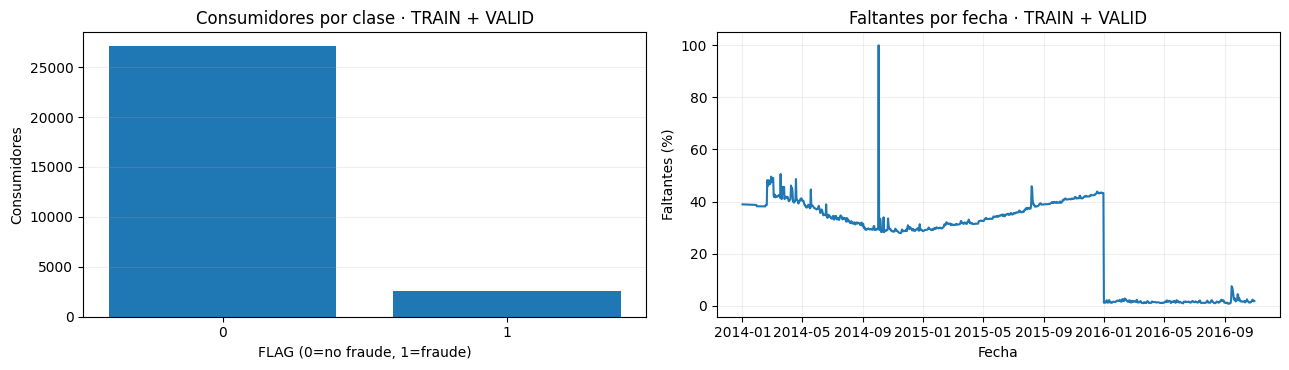

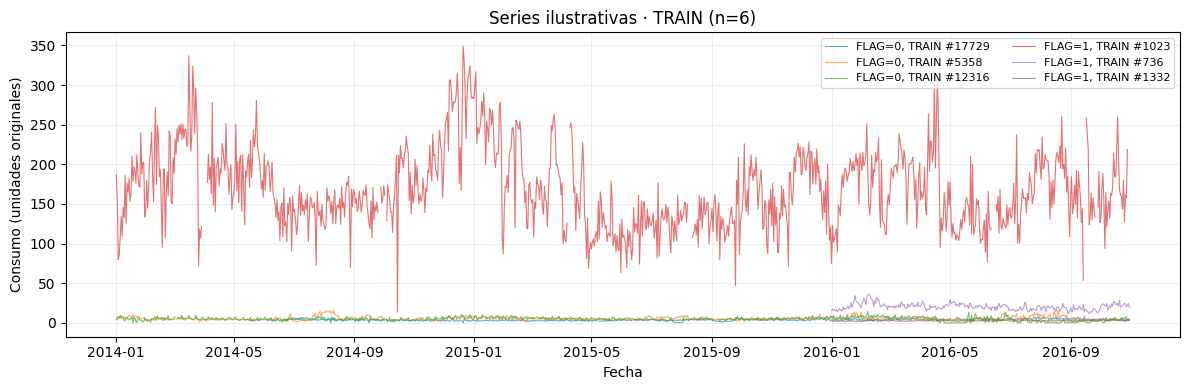

2026-11-24 21:53:04,278 | INFO | FIN: EDA: figuras (2.5 s)


In [9]:
with etapa('EDA: figuras'):
    fig,axs=plt.subplots(1,2,figsize=(13,3.8))
    axs[0].bar(tabla_clases.FLAG.astype(str),tabla_clases.consumidores); axs[0].set(title='Consumidores por clase · TRAIN + VALID',xlabel='FLAG (0=no fraude, 1=fraude)',ylabel='Consumidores'); axs[0].grid(axis='y',alpha=.2)
    axs[1].plot(fechas_calendario,faltantes_fecha.porcentaje); axs[1].set(title='Faltantes por fecha · TRAIN + VALID',xlabel='Fecha',ylabel='Faltantes (%)'); axs[1].grid(alpha=.2)
    fig.tight_layout(); fig.savefig(RUTA/'figuras'/'eda_distribucion_nulos.png',dpi=130); plt.show(); plt.close(fig)
    rng=np.random.default_rng(CFG.semilla); disponibles={c:np.flatnonzero(y_train==c) for c in (0,1)}
    seleccion=[(c,int(i)) for c in (0,1) for i in rng.choice(disponibles[c],size=min(3,len(disponibles[c])),replace=False)]
    if seleccion:
        fig,ax=plt.subplots(figsize=(12,4))
        for c,i in seleccion: ax.plot(fechas_calendario,X_train_raw[i],lw=.8,alpha=.65,label=f'FLAG={c}, TRAIN #{i}')
        ax.set(title=f'Series ilustrativas · TRAIN (n={len(seleccion)})',xlabel='Fecha',ylabel='Consumo (unidades originales)'); ax.legend(ncol=2,fontsize=8); ax.grid(alpha=.2)
        fig.tight_layout(); fig.savefig(RUTA/'figuras'/'eda_series_ejemplo.png',dpi=130); plt.show(); plt.close(fig)


### 1.4. Resultados e interpretación del EDA

El conjunto de desarrollo reunió 29.660 consumidores y 1.034 fechas: 27.130 consumidores (91,47 %) con `FLAG=0` y 2.530 (8,53 %) con `FLAG=1`. La matriz contiene 30.668.440 observaciones consumidor-fecha, de las cuales 7.857.551 (25,621 %) son faltantes.

La tasa media de faltantes fue 25,10 % para `FLAG=0` y 31,20 % para `FLAG=1`. Esta diferencia es descriptiva; no demuestra causalidad ni identifica el mecanismo que produjo las ausencias. No se observaron infinitos ni consumos negativos en TRAIN+VALID y se contabilizaron 4.045.581 ceros. Faltantes y ceros se contaron en matrices completas; los cuartiles y límites intercuartílicos se estimaron mediante muestreo proporcional reproducible.

## 2. Interpolación y tratamiento de faltantes

Se compararon cuatro técnicas con el mismo orden cronológico basado en días reales. La interpolación por vecinos promedió vecinos originales; la regresión iterativa se ajustó solo en TRAIN; la interpolación lineal utilizó los tiempos reales y conservó los extremos observados; PCHIP interpoló por tramos sin extrapolar fuera del rango observado. Las filas totalmente vacías se completaron con cero.

El imputador iterativo se configuró con `max_iter=2`, `n_nearest_features=12` y `min_value=0`. Todas las técnicas conservaron forma, observaciones originales y orden de fechas.

In [10]:
from scipy.interpolate import PchipInterpolator
from sklearn.experimental import enable_iterative_imputer  # noqa: F401
from sklearn.impute import IterativeImputer
from sklearn.linear_model import LinearRegression

INTERPOLACIONES=('vecinos','iterativa','lineal','pchip')

def _validar_X_t(X,t=None):
    x=np.asarray(X)
    if x.ndim!=2 or not np.issubdtype(x.dtype,np.number): raise ValueError('X debe ser una matriz numérica 2D.')
    if np.isinf(x).any(): raise ValueError('X contiene infinitos; conviértalos explícitamente a NaN.')
    if t is None: return x,None
    eje=np.asarray(t,dtype=np.float64)
    if eje.ndim!=1 or len(eje)!=x.shape[1] or not np.isfinite(eje).all() or (len(eje)>1 and not np.all(np.diff(eje)>0)):
        raise ValueError('t debe tener un tiempo finito, creciente y compatible por columna.')
    return x,eje

def interpolar_vecinos(X,chunk=512,mostrar=True):
    """Promedia los dos vecinos inmediatos originales; si falta uno, usa cero."""
    x,_=_validar_X_t(X)
    if int(chunk)<=0: raise ValueError('chunk debe ser positivo.')
    out=np.asarray(x,dtype=np.float32).copy(); filas=np.flatnonzero(np.isnan(out).any(axis=1))
    for ini in tqdm(range(0,len(filas),int(chunk)),desc='Vecinos · consumidores',unit='bloque',disable=not mostrar):
        ids=filas[ini:ini+int(chunk)]; original=out[ids].copy(); faltan=np.isnan(original)
        left=np.full_like(original,np.nan); right=np.full_like(original,np.nan)
        if original.shape[1]>1: left[:,1:]=original[:,:-1]; right[:,:-1]=original[:,1:]
        ambos=np.isfinite(left)&np.isfinite(right); vals=np.zeros_like(original)
        vals[ambos]=((left[ambos].astype(np.float64)+right[ambos].astype(np.float64))/2).astype(np.float32)
        original[faltan]=vals[faltan]; out[ids]=original
    return out

def interpolar_lineal(X,t,mostrar=True):
    """Interpolación con eje temporal real, extremos cercanos y filas vacías en cero."""
    x,eje=_validar_X_t(X,t); out=np.asarray(x,dtype=np.float32).copy()
    filas=np.flatnonzero(np.isnan(out).any(axis=1))
    for i in tqdm(filas,desc='Lineal · consumidores con faltantes',unit='consumidor',disable=not mostrar):
        v=out[i]; ok=np.isfinite(v); n=int(ok.sum())
        if n==0: v[:]=0
        elif n==1: v[~ok]=v[ok][0]
        else: v[~ok]=np.interp(eje[~ok],eje[ok],v[ok]).astype(np.float32)
    return out

def interpolar_pchip(X,t,mostrar=True):
    """PCHIP en huecos interiores, sin extrapolar en extremos."""
    x,eje=_validar_X_t(X,t); out=np.asarray(x,dtype=np.float32).copy()
    filas=np.flatnonzero(np.isnan(out).any(axis=1))
    for i in tqdm(filas,desc='PCHIP · consumidores con faltantes',unit='consumidor',disable=not mostrar):
        v=out[i]; ok=np.isfinite(v); n=int(ok.sum())
        if n==0: v[:]=0; continue
        if n==1: v[~ok]=v[ok][0]; continue
        faltan=~ok; interp=PchipInterpolator(eje[ok],v[ok].astype(np.float64),extrapolate=False)
        vals=np.interp(eje[faltan],eje[ok],v[ok]).astype(np.float64)
        dentro=(eje[faltan]>=eje[ok][0])&(eje[faltan]<=eje[ok][-1]); vals[dentro]=interp(eje[faltan][dentro])
        v[faltan]=vals.astype(np.float32)
    return out

class ImputadorIterativoOriginal:
    def __init__(self,semilla=111):
        self.modelo=IterativeImputer(estimator=LinearRegression(),max_iter=2,n_nearest_features=12,min_value=0,
            random_state=semilla,verbose=2,initial_strategy='median',skip_complete=True,keep_empty_features=True)
        self._ajustado=False; self.advertencias=[]
    def fit_transform(self,X):
        x,_=_validar_X_t(X); orig=np.asarray(x,dtype=np.float32)
        with warnings.catch_warnings(record=True) as capturadas:
            warnings.simplefilter('always'); out=self.modelo.fit_transform(orig).astype(np.float32,copy=False)
        self.advertencias=[str(w.message) for w in capturadas]
        for mensaje in self.advertencias: print('Advertencia IterativeImputer:',mensaje)
        validar_imputacion(orig,out); self._ajustado=True
        return out
    def transform(self,X):
        if not self._ajustado: raise RuntimeError('Ajuste el imputador con TRAIN antes de transformar VALID/TEST.')
        x,_=_validar_X_t(X); orig=np.asarray(x,dtype=np.float32)
        with warnings.catch_warnings(record=True) as capturadas:
            warnings.simplefilter('always'); out=self.modelo.transform(orig).astype(np.float32,copy=False)
        self.advertencias.extend(str(w.message) for w in capturadas)
        for mensaje in (str(w.message) for w in capturadas): print('Advertencia IterativeImputer:',mensaje)
        validar_imputacion(orig,out)
        return out

def validar_imputacion(X,Y):
    x,_=_validar_X_t(X); y=np.asarray(Y)
    if y.shape!=x.shape: raise ValueError('La salida debe conservar la forma de X.')
    if y.dtype!=np.float32: raise TypeError('La salida debe ser float32.')
    if not np.isfinite(y).all(): raise ValueError('La imputación dejó NaN o infinito.')
    obs=np.isfinite(x)
    if not np.allclose(y[obs],x[obs],rtol=1e-5,atol=1e-5): raise ValueError('Se modificó un valor originalmente observado.')
    return True

def interpolacion_pares(nombre,train,valid,t,mostrar=True):
    if nombre not in INTERPOLACIONES: raise ValueError(f'Método desconocido {nombre}; opciones: {INTERPOLACIONES}.')
    _validar_X_t(train,t); _validar_X_t(valid,t)
    if np.asarray(train).shape[1]!=np.asarray(valid).shape[1]: raise ValueError('TRAIN y VALID deben compartir fechas.')
    if nombre=='iterativa':
        imp=ImputadorIterativoOriginal(CFG.semilla); a=imp.fit_transform(train); b=imp.transform(valid)
    elif nombre=='vecinos':
        a=interpolar_vecinos(train,CFG.chunk_filas,mostrar); b=interpolar_vecinos(valid,CFG.chunk_filas,mostrar)
    else:
        f=interpolar_lineal if nombre=='lineal' else interpolar_pchip
        a=f(train,t,mostrar); b=f(valid,t,mostrar)
    validar_imputacion(train,a); validar_imputacion(valid,b); return a,b


### 2.3. Comprobaciones sintéticas

Las pruebas incluidas en esta celda verifican contratos de software con entradas artificiales. Sus valores no son resultados científicos del conjunto eléctrico.

In [11]:
# Pruebas sintéticas acotadas; no usan el CSV ni entrenan experimentos
_demo=np.array([[1,np.nan,3,4],[np.nan,2,np.nan,6],[np.nan]*4,[5,5,5,5],[np.nan,-5,np.nan,np.nan],[-4,np.nan,-2,np.nan],[np.nan,7,7,np.nan]],dtype=np.float32)
_t=np.array([0.,1.,3.,8.],dtype=np.float64)
for _nombre,_f in [('vecinos',lambda z:interpolar_vecinos(z,chunk=2,mostrar=False)),('lineal',lambda z:interpolar_lineal(z,_t,False)),('pchip',lambda z:interpolar_pchip(z,_t,False))]:
    _antes=_demo.copy(); _out=_f(_demo)
    assert validar_imputacion(_demo,_out) and _out.shape==_demo.shape and _out.dtype==np.float32
    assert np.array_equal(_demo,_antes,equal_nan=True)
    print('PASS:',_nombre,'| forma, tipo, finitud, observados e inmutabilidad')
assert interpolar_vecinos([[1,np.nan,3]],mostrar=False)[0,1]==2
assert interpolar_vecinos([[np.nan,2,np.nan]],mostrar=False).tolist()==[[0.,2.,0.]]
assert np.isclose(interpolar_lineal([[1,np.nan,5]],[0,1,3],False)[0,1],7/3,rtol=1e-6)
assert interpolar_lineal([[np.nan,-5,np.nan]],[0,1,4],False).tolist()==[[-5.,-5.,-5.]]
assert interpolar_pchip([[np.nan,-5,np.nan]],[0,1,4],False).tolist()==[[-5.,-5.,-5.]]
for _xx,_tt in [(np.ones((2,3)),[0,1]),(np.ones((2,3)),[0,1,1])]:
    try: interpolar_lineal(_xx,_tt,False)
    except ValueError: pass
    else: raise AssertionError('Se esperaba rechazar eje temporal incompatible.')
print('PASS: vecinos inmediatos, fechas irregulares y validación del eje')
del _demo,_t,_nombre,_f,_antes,_out,_xx,_tt


PASS: vecinos | forma, tipo, finitud, observados e inmutabilidad
PASS: lineal | forma, tipo, finitud, observados e inmutabilidad
PASS: pchip | forma, tipo, finitud, observados e inmutabilidad
PASS: vecinos inmediatos, fechas irregulares y validación del eje


### 2.4. Comparación e interpretación de las interpolaciones

Las cuatro alternativas se evaluaron mediante PR-AUC en VALID, manteniendo constantes el tratamiento 3σ, las 17 estadísticas, SMOTE y Random Forest de referencia.

| Interpolación | PR-AUC en VALID |
|---|---:|
| Iterativa | **0,256346** |
| Vecinos | 0,248981 |
| PCHIP | 0,237058 |
| Lineal | 0,230637 |

Se seleccionó la interpolación iterativa porque obtuvo la mayor PR-AUC, conforme al criterio fijado. El ajuste con dos iteraciones emitió una advertencia: no se alcanzó el criterio de parada temprana. Por ello, el resultado corresponde al límite configurado y no acredita convergencia.

## 3. Tratamiento de valores extremos

Se compararon tres transformaciones por consumidor sobre las series interpoladas. 3σ limita picos superiores mediante media + 3 desviaciones estándar; IQR recorta a los límites intercuartílicos con piso cero; MAD utiliza la mediana y la desviación absoluta mediana escalada. Ningún método elimina consumidores y las tres salidas mantienen las filas.

In [12]:
# 3.2. Tratamiento de valores atípicos: 3σ / IQR / MAD
OUTLIERS=('sigma3','iqr','mad')

def tratar_outliers(X,metodo,chunk=512,mostrar=True):
    if metodo not in OUTLIERS: raise ValueError('Outlier desconocido: '+str(metodo))
    if not np.isfinite(X).all(): raise ValueError('Interpola antes de detectar outliers')
    out=np.empty_like(X,dtype=np.float32)
    cambiadas=0
    for ini in tqdm(range(0,len(X),chunk),desc='Outliers '+metodo,disable=not mostrar):
        a=X[ini:ini+chunk]
        if metodo=='sigma3':
            media=np.mean(a,axis=1,keepdims=True,dtype=np.float64)
            sigma=np.std(a,axis=1,keepdims=True,dtype=np.float64)
            bajo=np.full_like(media,-np.inf)
            alto=media+3*sigma
        elif metodo=='iqr':
            q1,q3=np.percentile(a,[25,75],axis=1)
            dif=(q3-q1)[:,None]
            bajo=np.maximum(0,(q1[:,None]-1.5*dif))
            alto=q3[:,None]+1.5*dif
            mascara=(dif==0)
            bajo=np.where(mascara,-np.inf,bajo);alto=np.where(mascara,np.inf,alto)
        else:
            med=np.median(a,axis=1,keepdims=True)
            mad=np.median(np.abs(a-med),axis=1,keepdims=True)
            escala=1.4826*mad
            bajo=np.maximum(0,med-3*escala);alto=med+3*escala
            bajo=np.where(mad==0,-np.inf,bajo);alto=np.where(mad==0,np.inf,alto)
        alto=np.maximum(alto,bajo)
        b=np.minimum(np.maximum(a,bajo),alto).astype(np.float32)
        cambiadas+=int(np.count_nonzero(b!=a))
        out[ini:ini+len(a)]=b
    assert out.shape==X.shape and np.isfinite(out).all()
    return out,cambiadas

### 3.3. Comparación de tratamientos

Las alternativas se compararon con interpolación iterativa, 17 estadísticas, SMOTE y Random Forest constantes.

| Tratamiento | PR-AUC en VALID | Recall de fraude |
|---|---:|---:|
| 3σ | **0,256346** | 0,545455 |
| IQR | 0,239720 | 0,561265 |
| MAD | 0,231332 | 0,577075 |

Se seleccionó 3σ por su mayor PR-AUC, aunque IQR y MAD alcanzaron mayor recall a umbral fijo. La decisión priorizó el ranking de casos según el criterio preestablecido. Un recorte más agresivo puede reducir extremos ruidosos, pero también ocultar patrones útiles para detectar fraude; los resultados no identifican qué valores cumplen cada papel.

In [13]:
# Series sintéticas para distinguir las reglas y contar cada recorte.
_series=np.vstack([np.r_[np.linspace(1,5,99),200], np.full(100,5)]).astype(np.float32)
_original=_series.copy()
_picos=[]
for metodo in OUTLIERS:
    _tratadas,_conteo=tratar_outliers(_series,metodo,chunk=1,mostrar=False)
    assert _tratadas.shape==_series.shape and _tratadas.dtype==np.float32
    assert np.isfinite(_tratadas).all() and np.array_equal(_series,_original)
    assert np.array_equal(_tratadas[1],_series[1])
    assert _conteo==np.count_nonzero(_tratadas!=_series)==1
    assert _tratadas[0,-1]<200
    _picos.append(_tratadas[0,-1])
    print('PASS',metodo,'| modificados=',_conteo,'| pico recortado=',round(float(_picos[-1]),2))
assert len(set(_picos))==len(OUTLIERS)

_negativos=np.array([[-10,-9,-9,-9,-8,-8,-7,-7]],dtype=np.float32)
_sin_dispersion=np.array([[-5,-5,-5,-5,-5,-5,-5,200]],dtype=np.float32)
for metodo in ('iqr','mad'):
    _tratadas,_conteo=tratar_outliers(_negativos,metodo,mostrar=False)
    assert (_tratadas==0).all() and _conteo==_negativos.size
    _tratadas,_conteo=tratar_outliers(_sin_dispersion,metodo,mostrar=False)
    assert np.array_equal(_tratadas,_sin_dispersion) and _conteo==0
print('PASS: piso de cero y conservación de filas con IQR/MAD cero.')
del _series,_original,_picos,_tratadas,_conteo,_negativos,_sin_dispersion

PASS sigma3 | modificados= 1 | pico recortado= 63.88
PASS iqr | modificados= 1 | pico recortado= 7.06
PASS mad | modificados= 1 | pico recortado= 7.56
PASS: piso de cero y conservación de filas con IQR/MAD cero.


## 4. Características estadísticas

Se calcularon las 17 estadísticas originales por consumidor. Las definiciones y el orden se mantuvieron para permitir trazabilidad: suma, media, mediana, desviación estándar, varianza, rango, curtosis, kstat, KStatvar, cuartiles, norma, IQR, percentiles y desviación absoluta mediana. Los parámetros compartidos para ICA y PLS se ajustan con TRAIN.

In [14]:
# 4.2. Extracción por bloques: 17 características de Generico.py
from scipy.stats import kurtosis,kstat,kstatvar
FEATURES=[
 'Sum','Mean','Median','Standard_Dev','Variance','Peak_to_Peak','Kurtosis',
 'kstat','KStatvar','Quartile_1','Quartile_3','Norm','IQR',
 'Percentile_15','Percentile_65','Percentile_85','Median_Absolute_Deviation']
assert len(FEATURES)==17

def extraer_17(X,chunk=512,mostrar=True):
    if not np.isfinite(X).all(): raise ValueError('Características requieren datos interpolados y finitos')
    f=np.empty((len(X),17),dtype=np.float32)
    for ini in tqdm(range(0,len(X),chunk),desc='17 estadísticas por bloques',disable=not mostrar):
        a=X[ini:ini+chunk].astype(np.float64,copy=False)
        q15,q25,q65,q75,q85=np.percentile(a,[15,25,65,75,85],axis=1)
        media=a.mean(axis=1)
        med=np.median(a,axis=1)
        with warnings.catch_warnings():
            warnings.simplefilter('ignore',RuntimeWarning)
            cur=kurtosis(a,axis=1,bias=True)
            ks=kstat(a,n=2,axis=1)
            ksv=kstatvar(a,n=2,axis=1)
        columnas=[a.sum(axis=1),media,med,np.std(a,axis=1,ddof=1),
            np.var(a,axis=1,ddof=1),np.ptp(a,axis=1),cur,
            ks,ksv,q25,q75,np.linalg.norm(a,axis=1),q75-q25,
            q15,q65,q85,np.median(np.abs(a-med[:,None]),axis=1)]
        bloque=np.column_stack(columnas)
        bloque=np.nan_to_num(bloque,nan=0.0,posinf=0.0,neginf=0.0)
        f[ini:ini+len(a)]=bloque.astype(np.float32)
    assert f.shape==(len(X),17) and np.isfinite(f).all()
    return f

In [15]:
_series=np.array([[1,2,3,4],[5,5,5,5]],dtype=np.float32)
_calculadas=extraer_17(_series,chunk=1,mostrar=False)
_esperadas=[
    10,2.5,2.5,np.sqrt(5/3),5/3,3,-1.36,5/3,kstatvar(_series[0].astype(float),n=2),
    1.75,3.25,np.sqrt(30),1.5,1.45,2.95,3.55,1,
]
_constante=[20,5,5,0,0,0,0,0,0,5,5,10,0,5,5,5,0]
assert _calculadas.shape==(2,17) and _calculadas.dtype==np.float32
np.testing.assert_allclose(_calculadas,[_esperadas,_constante],rtol=1e-6,atol=1e-6)
assert FEATURES==[
    'Sum','Mean','Median','Standard_Dev','Variance','Peak_to_Peak','Kurtosis',
    'kstat','KStatvar','Quartile_1','Quartile_3','Norm','IQR','Percentile_15',
    'Percentile_65','Percentile_85','Median_Absolute_Deviation',
]
print('PASS: valores, nombres y orden de las 17 estadísticas, incluidas las filas constantes.')
del _series,_calculadas,_esperadas,_constante

PASS: valores, nombres y orden de las 17 estadísticas, incluidas las filas constantes.


### 4.3. Efecto descriptivo del tratamiento 3σ

La tabla y los gráficos comparan muestras de hasta 500 consumidores por clase en TRAIN y VALID, antes y después de 3σ. En esas muestras disminuyeron la mediana y el IQR de `Peak_to_Peak`, `Variance`, `Kurtosis` y `KStatvar`. Por ejemplo, el IQR de `KStatvar` pasó de 66,20 a 14,67 en TRAIN y de 119,89 a 18,00 en VALID.

Estas estadísticas describen las muestras graficadas, no toda la población. En cambio, el conteo de celdas modificadas corresponde a las matrices completas: 201.587 en TRAIN y 50.000 en VALID. La reducción de dispersión no demuestra que una característica individual haya mejorado la predicción; ese efecto no se aisló experimentalmente.

In [16]:
def comparar_estadisticas_outliers(particiones, metodo):
    columnas_grafico=('Mean','Standard_Dev','IQR')
    fig,ejes=plt.subplots(len(particiones),len(columnas_grafico),figsize=(13,7),squeeze=False)
    rng=np.random.default_rng(CFG.semilla)
    filas=[]
    for (nombre, interpoladas, caracteristicas, etiquetas), panel in zip(particiones,ejes):
        muestras=[]
        for clase in np.unique(etiquetas):
            grupo=np.flatnonzero(etiquetas==clase)
            muestras.append(rng.choice(grupo,size=min(500,len(grupo)),replace=False))
        indices=np.concatenate(muestras)
        clases=etiquetas[indices]
        antes=extraer_17(interpoladas[indices],CFG.chunk_filas,mostrar=False).astype(np.float64)
        despues=caracteristicas[indices]
        mediana_antes=np.median(antes,axis=0)
        mediana_despues=np.median(despues,axis=0)
        iqr_antes=np.percentile(antes,75,axis=0)-np.percentile(antes,25,axis=0)
        iqr_despues=np.percentile(despues,75,axis=0)-np.percentile(despues,25,axis=0)
        magnitud=np.abs(antes).sum(axis=0)+np.abs(despues).sum(axis=0,dtype=np.float64)
        cambio=np.divide(np.abs(despues-antes).sum(axis=0),magnitud,
                         out=np.zeros_like(magnitud),where=magnitud>0)
        for col, estadistica in enumerate(FEATURES):
            filas.append({'particion':nombre,'estadistica':estadistica,'n_consumidores':len(indices),
                          'mediana_antes':mediana_antes[col],'mediana_despues':mediana_despues[col],
                          'iqr_antes':iqr_antes[col],'iqr_despues':iqr_despues[col],
                          'cambio_relativo':cambio[col]})
        for ax, estadistica in zip(panel,columnas_grafico):
            col=FEATURES.index(estadistica)
            cajas,rotulos=[],[]
            for clase in np.unique(clases):
                mascara=clases==clase
                cajas.extend([antes[mascara,col],despues[mascara,col]])
                rotulos.extend([f'{clase} · Antes',f'{clase} · Después'])
            ax.boxplot(cajas,showfliers=False)
            ax.set_xticks(range(1,len(rotulos)+1),rotulos,rotation=15)
            ax.set_title(f'{nombre} | {estadistica}')
            ax.set_xlabel('FLAG y momento del recorte')

    fig.suptitle(f'Efecto de {metodo} sobre las estadísticas | {CFG.modo}')
    fig.tight_layout()
    fig.savefig(RUTA/'figuras'/'estadisticas_antes_despues_outliers.png',dpi=150)
    plt.show()
    plt.close(fig)
    tabla=pd.DataFrame(filas).sort_values(['particion','cambio_relativo','estadistica'],
                                       ascending=[True,False,True])
    exportar_csv(tabla,RUTA/'metricas'/'cambios_estadisticas_outliers.csv')
    display(tabla.groupby('particion',sort=False).head(5).round(5))

## 5. Balanceo de clases: SMOTE y ADASYN

El conjunto presentaba desbalance de clases. SMOTE generó ejemplos de fraude interpolando entre vecinos de esa clase; ADASYN concentró más generación en regiones donde los vecinos incluían más casos de la clase mayoritaria.

Ambos métodos se aplicaron solo a TRAIN después de transformar los datos. VALID y TEST conservaron su distribución original para una evaluación comparable con la prevalencia observada.

In [17]:
# 5.2. Balanceo de la representación de entrenamiento
from imblearn.over_sampling import ADASYN, SMOTE
from threadpoolctl import threadpool_limits

BALANCEADORES = ('smote', 'adasyn')

def balancear_train(Z_train, y_train, metodo, mostrar=True):
    if metodo not in BALANCEADORES:
        raise ValueError(f'Balanceador no reconocido: {metodo}')
    caracteristicas = np.asarray(Z_train, dtype=np.float32)
    etiquetas = np.asarray(y_train)
    if (caracteristicas.ndim != 2 or caracteristicas.shape[1] == 0
            or etiquetas.ndim != 1 or len(caracteristicas) != len(etiquetas)):
        raise ValueError('Se requiere una matriz 2D y un vector de etiquetas alineado.')
    if not np.isfinite(caracteristicas).all():
        raise ValueError('El balanceo requiere características finitas.')
    if not np.isin(etiquetas, [0, 1]).all():
        raise ValueError('El balanceo requiere etiquetas binarias 0 y 1.')
    etiquetas = etiquetas.astype(np.int8, copy=False)
    mayoria, minoria = np.bincount(etiquetas, minlength=2)
    vecinos = CFG.k_vecinos_balance
    objetivo = CFG.estrategia_sintetica
    if not 0 < objetivo <= 1:
        raise ValueError('La proporción objetivo minoría/mayoría debe estar en (0, 1].')
    if mayoria <= minoria or minoria <= vecinos:
        raise ValueError(f'{metodo.upper()} requiere fraude como clase minoritaria y al menos '
                         f'{vecinos + 1} casos de fraude. Conteos 0/1: {mayoria}/{minoria}.')
    if int(mayoria * objetivo) <= minoria:
        raise ValueError(f'{metodo.upper()} no puede agregar muestras: la proporción '
                         f'{objetivo:g} ya se alcanza o no admite otra muestra entera.')
    parametros = {'sampling_strategy': objetivo, 'random_state': CFG.semilla}
    if metodo == 'smote':
        balanceador = SMOTE(k_neighbors=vecinos, **parametros)
    else:
        balanceador = ADASYN(n_neighbors=vecinos, **parametros)

    inicio = time.perf_counter()
    try:
        with threadpool_limits(limits=CFG.n_jobs):
            nuevos_X, nuevas_y = balanceador.fit_resample(caracteristicas, etiquetas)
    except (ValueError, RuntimeError) as error:
        raise ValueError(f'{metodo.upper()} no pudo sobremuestrear TRAIN/DEV: {error}') from error
    nuevos_X = np.asarray(nuevos_X, dtype=np.float32)
    nuevas_y = np.asarray(nuevas_y, dtype=np.int8)
    conteos = np.bincount(nuevas_y, minlength=2)
    sinteticos = int(conteos[1] - minoria)
    if (nuevos_X.shape != (len(nuevas_y), caracteristicas.shape[1])
            or conteos[0] != mayoria or sinteticos <= 0 or not np.isfinite(nuevos_X).all()):
        raise RuntimeError(f'{metodo.upper()} devolvió un sobremuestreo inválido.')
    if mostrar:
        segundos = time.perf_counter() - inicio
        print(f'{metodo.upper()} | clases 0/1: {mayoria}/{minoria} → {conteos[0]}/{conteos[1]} '
              f'| sintéticos={sinteticos} | proporción={conteos[1] / conteos[0]:.3f} '
              f'| {segundos:.3f} s', flush=True)
    return nuevos_X, nuevas_y

### 5.3. Comprobación funcional

La celda siguiente prueba los balanceadores con datos sintéticos y verifica conteos, forma, tipos, reproducibilidad y preservación de entradas. Estas salidas validan software; no son métricas del dataset real.

In [18]:
def probar_balanceadores():
    generador = np.random.default_rng(CFG.semilla)
    X = np.vstack([generador.normal(0, 1, (80, 4)),
                   generador.normal(0.7, 1, (20, 4))]).astype(np.float32)
    y = np.repeat([0, 1], [80, 20]).astype(np.int8)
    originales_X, originales_y = X.copy(), y.copy()
    for metodo in BALANCEADORES:
        X_res, y_res = balancear_train(X, y, metodo)
        X_repetido, y_repetido = balancear_train(X, y, metodo, mostrar=False)
        assert X_res.shape == (len(y_res), X.shape[1]) and X_res.dtype == np.float32
        assert y_res.dtype == np.int8 and np.isfinite(X_res).all()
        np.testing.assert_array_equal(X_res, X_repetido)
        np.testing.assert_array_equal(y_res, y_repetido)
        np.testing.assert_array_equal(X_res[:len(X)], originales_X)
        np.testing.assert_array_equal(y_res[:len(y)], originales_y)
        assert set(y_res) == {0, 1} and (y_res == 0).sum() == 80 and (y_res == 1).sum() > 20
        if metodo == 'smote':
            assert (y_res == 1).sum() == int(80 * CFG.estrategia_sintetica)
        print(f'PASS {metodo.upper()} (prueba sintética)')
    np.testing.assert_array_equal(X, originales_X)
    np.testing.assert_array_equal(y, originales_y)
    separadas = np.repeat(y[:, None] * 10.0, 4, axis=1)
    try:
        balancear_train(separadas, y, 'adasyn', mostrar=False)
    except ValueError as error:
        assert str(error).startswith('ADASYN no pudo sobremuestrear TRAIN/DEV:')
    else:
        raise AssertionError('ADASYN debía informar que faltan vecindarios mixtos.')
    print('PASS ADASYN con clases separadas (error esperado)')

probar_balanceadores()

SMOTE | clases 0/1: 80/20 → 80/64 | sintéticos=44 | proporción=0.800 | 0.134 s
PASS SMOTE (prueba sintética)
ADASYN | clases 0/1: 80/20 → 80/62 | sintéticos=42 | proporción=0.775 | 0.090 s
PASS ADASYN (prueba sintética)
PASS ADASYN con clases separadas (error esperado)


## 6. Extracción de características y representaciones

Se evaluaron tres representaciones con funciones distintas: el Autoencoder comprimió la serie diaria de 1.034 valores en 32 dimensiones; ICA obtuvo componentes independientes de las 17 estadísticas sin usar etiquetas; PLS produjo componentes supervisados a partir de esas estadísticas y las etiquetas de TRAIN.

Cada representación se evaluó con un clasificador asignado: Autoencoder–XGBoost, ICA–Random Forest y PLS–LightGBM. Las seis configuraciones cruzaron estos pares con SMOTE y ADASYN. La comparación corresponde a pares completos y las entradas difieren: el Autoencoder recibió la serie temporal, mientras ICA y PLS recibieron estadísticas resumidas.

### 6.1. Análisis de componentes independientes (ICA)

ICA se ajustó sin etiquetas sobre las 17 estadísticas estandarizadas de TRAIN, con FastICA, hasta 10 componentes, `whiten='unit-variance'`, semilla 111, máximo de 500 iteraciones y tolerancia 0,001. VALID y TEST se proyectaron con el escalador y el extractor ajustados en TRAIN. Una advertencia de convergencia detuvo el ajuste.

In [19]:
# 6.1.1. ICA
from sklearn.decomposition import FastICA
from sklearn.exceptions import ConvergenceWarning
from sklearn.utils.validation import check_array

class ExtractorICA:
    def __init__(self, n_components=10, semilla=111):
        self.n_components = n_components
        self.semilla = semilla
        self._ajustado = False

    def fit(self, X, y=None):
        self._ajustado = False
        X = check_array(X, dtype=np.float32, ensure_min_samples=2)
        escalador = StandardScaler()
        X_escalado = escalador.fit_transform(X)
        with threadpool_limits(limits=CFG.n_jobs):
            rango = np.linalg.matrix_rank(X_escalado)
            componentes = min(self.n_components, X.shape[1], len(X) - 1, rango)
            if componentes < 1:
                raise ValueError('ICA requiere al menos un componente con variación en TRAIN/DEV.')
            modelo = FastICA(n_components=componentes, whiten='unit-variance',
                             random_state=self.semilla, max_iter=500, tol=0.001)
            try:
                with warnings.catch_warnings():
                    warnings.simplefilter('error', ConvergenceWarning)
                    modelo.fit(X_escalado)
            except ConvergenceWarning as error:
                raise RuntimeError(f'ICA no convergió con {componentes} componentes '
                                   f'tras {modelo.max_iter} iteraciones.') from error
        self.scaler = escalador
        self.modelo = modelo
        print(f'ICA | componentes={componentes}/{self.n_components} | rango={rango} '
              f'| iteraciones={modelo.n_iter_}', flush=True)
        self._ajustado = True
        return self

    def transform(self, X):
        if not self._ajustado:
            raise RuntimeError('ICA requiere un ajuste válido antes de transformar.')
        representacion = self.modelo.transform(self.scaler.transform(X)).astype(np.float32)
        if not np.isfinite(representacion).all():
            raise RuntimeError('ICA produjo componentes no finitos.')
        return representacion

### 6.2. Mínimos cuadrados parciales (PLS)

PLS aprendió una proyección supervisada de hasta ocho componentes a partir de las 17 estadísticas y las etiquetas de TRAIN (`PLSRegression(scale=True, max_iter=500)`). La dimensión se limitó por el número de filas y el rango de la matriz. VALID y TEST se transformaron con el modelo ya ajustado.

In [20]:
# 6.2.1. PLS
from sklearn.cross_decomposition import PLSRegression

class ExtractorPLS:
    def __init__(self, n_components=8):
        self.n_components = n_components
        self._ajustado = False

    def fit(self, X, y):
        self._ajustado = False
        if y is None:
            raise ValueError('PLS requiere las etiquetas de TRAIN/DEV.')
        X = check_array(X, dtype=np.float32, ensure_min_samples=2)
        etiquetas = np.asarray(y)
        if (etiquetas.shape != (len(X),) or not np.isin(etiquetas, [0, 1]).all()
                or np.unique(etiquetas).size != 2):
            raise ValueError('PLS requiere un vector alineado con ambas clases 0 y 1.')
        with threadpool_limits(limits=CFG.n_jobs):
            rango = np.linalg.matrix_rank(StandardScaler().fit_transform(X))
            componentes = min(self.n_components, X.shape[1], len(X) - 1, rango)
            if componentes < 1:
                raise ValueError('PLS requiere al menos un componente con variación en TRAIN/DEV.')
            modelo = PLSRegression(n_components=componentes, scale=True, max_iter=500)
            try:
                with warnings.catch_warnings():
                    warnings.simplefilter('error', ConvergenceWarning)
                    modelo.fit(X, etiquetas.astype(np.float64))
            except ConvergenceWarning as error:
                raise RuntimeError(f'PLS no convergió con {componentes} componentes.') from error
        componentes_activos = len(modelo.n_iter_)
        if componentes_activos == 0:
            raise RuntimeError('PLS no obtuvo componentes activos del entrenamiento.')
        self.modelo = modelo
        self.componentes_activos = componentes_activos
        print(f'PLS | componentes activos={componentes_activos}/{self.n_components} '
              f'| rango={rango}', flush=True)
        self._ajustado = True
        return self

    def transform(self, X):
        if not self._ajustado:
            raise RuntimeError('PLS requiere un ajuste válido antes de transformar.')
        representacion = self.modelo.transform(X)[:, :self.componentes_activos].astype(np.float32)
        if not np.isfinite(representacion).all():
            raise RuntimeError('PLS produjo componentes no finitos.')
        return representacion

### 6.3. Autoencoder

El Autoencoder se configuró con una arquitectura simétrica `128 → 64 → 32 → 64 → 128 → D`, activaciones ReLU en las capas ocultas, salida lineal, pérdida MSE y `Adam(0.003)`. El escalador se ajustó solo con TRAIN; la reconstrucción se aprendió sin etiquetas y produjo una representación de 32 dimensiones.

El máximo fue de 20 épocas en modo `COMPLETO`. La curva de entrenamiento y validación se interpreta según los valores observados; por sí sola no demuestra convergencia monótona, retención de información útil ni ausencia de sobreajuste.

In [21]:
# 6.3.1. Autoencoder: encapsulación del escalador, encoder y seguimiento de épocas
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

class ProgresoEpocas(keras.callbacks.Callback):
    def __init__(self,total):
        super().__init__();self.total=total;self.barra=None
    def on_train_begin(self,logs=None):
        self.barra=tqdm(total=self.total,desc='Autoencoder | épocas',unit='época',leave=True)
    def on_epoch_end(self,epoch,logs=None):
        logs=logs or {}
        self.barra.update(1)
        self.barra.set_postfix(loss=f'{logs.get("loss",float("nan")):.4f}',
                             val_loss=f'{logs.get("val_loss",float("nan")):.4f}')
    def on_train_end(self,logs=None):
        if self.barra:self.barra.close()

class ExtractorAutoencoder:
    def __init__(self,semilla=111,modo='RAPIDO'):
        self.semilla=semilla;self.modo=modo;self._ajustado=False
    def fit(self,X,y=None):
        self._ajustado=False
        if X is None:
            raise TypeError('X no puede ser None.')
        if isinstance(X,str) or not hasattr(X,'__iter__'):
            raise TypeError('X debe ser una matriz numérica bidimensional (2D).')
        try:
            arr=np.asarray(X)
        except Exception as e:
            raise TypeError(f'X no es convertible a un arreglo numérico: {e}')
        if not np.issubdtype(arr.dtype,np.number):
            raise TypeError('X debe contener exclusivamente valores numéricos.')
        if arr.ndim!=2:
            raise ValueError(f'X debe ser una matriz 2D, se recibió ndim={arr.ndim}.')
        if arr.shape[1]<32:
            raise ValueError(f'Se requieren por lo menos 32 días de consumo para el Autoencoder, se recibió {arr.shape[1]}.')
        if not np.all(np.isfinite(arr)):
            raise ValueError('X contiene valores no finitos (NaN o Inf).')
        keras.utils.set_random_seed(self.semilla)
        self.scaler=StandardScaler()
        datos=self.scaler.fit_transform(arr).astype(np.float32)
        entrada=keras.Input(shape=(datos.shape[1],),name='serie_consumo')
        h=layers.Dense(128,activation='relu')(entrada)
        h=layers.Dense(64,activation='relu')(h)
        latente=layers.Dense(32,activation='linear',name='latente_32')(h)
        h=layers.Dense(64,activation='relu')(latente)
        h=layers.Dense(128,activation='relu')(h)
        salida=layers.Dense(datos.shape[1],activation='linear')(h)
        auto=keras.Model(entrada,salida,name='autoencoder_electricidad')
        self.encoder=keras.Model(entrada,latente,name='encoder_electricidad')
        auto.compile(optimizer=keras.optimizers.Adam(learning_rate=.003),loss='mse')
        n_ep=CFG.epochs_rapido if self.modo=='RAPIDO' else CFG.epochs_completo
        # validation_split solo segmenta TRAIN; no utiliza VALID científica.
        callbacks=[keras.callbacks.EarlyStopping(monitor='val_loss',patience=CFG.paciencia_ae,
                                                 restore_best_weights=True),ProgresoEpocas(n_ep)]
        with etapa('Ajustar Autoencoder en TRAIN'):
            hist=auto.fit(datos,datos,epochs=n_ep,batch_size=CFG.batch_ae,
                    shuffle=True,validation_split=0.1,verbose=0,callbacks=callbacks)
        self.historia={k:[float(x) for x in v] for k,v in hist.history.items()}
        self.autoencoder=auto
        self._ajustado=True
        del datos;gc.collect()
        return self
    def transform(self,X):
        if not getattr(self,'_ajustado',False):
            raise RuntimeError('Ajuste el ExtractorAutoencoder con fit() antes de transformar.')
        datos=self.scaler.transform(X).astype(np.float32)
        z=self.encoder.predict(datos,batch_size=max(256,CFG.batch_ae),verbose=0).astype(np.float32)
        del datos
        assert z.shape==(len(X),32) and np.isfinite(z).all()
        return z
    def fit_transform(self,X,y=None):
        return self.fit(X,y).transform(X)

### 6.4. Comprobaciones de interfaces

Las pruebas sintéticas verifican ajuste y transformación de ICA y PLS, dimensiones, tipos y uso de etiquetas solo durante el ajuste supervisado de PLS. Las salidas sintéticas son comprobaciones funcionales y no resultados del experimento real.

In [22]:
# Prueba sintética de ICA y PLS
def probar_extractores_estadisticos():
    generador = np.random.default_rng(CFG.semilla)
    fuentes = generador.laplace(size=(600, 5))
    X = (fuentes @ generador.normal(size=(5, 17))).astype(np.float32)
    X_train, X_valid, X_test = X[:500], X[500:550] + 10, X[550:] - 10
    y_train = (fuentes[:500, 0] + 0.4 * fuentes[:500, 1] > 0).astype(np.int8)

    def comprobar_rechazo_sin_ajuste(nombre, extractor):
        assert not extractor._ajustado
        try:
            extractor.transform(X_valid)
        except RuntimeError as error:
            assert nombre in str(error) and 'ajuste válido' in str(error)
        else:
            raise AssertionError(f'{nombre} aceptó transformar sin un ajuste válido.')

    for nombre, extractor, etiquetas in (
        ('ICA', ExtractorICA(), None), ('PLS', ExtractorPLS(), y_train),
    ):
        inicio = time.perf_counter()
        comprobar_rechazo_sin_ajuste(nombre, extractor)
        ajustado = extractor.fit(X_train, etiquetas)
        assert ajustado is extractor and extractor._ajustado
        atributo_pesos = 'components_' if nombre == 'ICA' else 'x_rotations_'
        pesos_train = getattr(extractor.modelo, atributo_pesos).copy()
        if nombre == 'ICA':
            escalador = extractor.scaler
            parametros = {atributo: np.copy(getattr(escalador, atributo)) for atributo in
                          ('mean_', 'var_', 'scale_', 'n_samples_seen_')}
        salidas = [extractor.transform(datos) for datos in (X_train, X_valid, X_test)]
        assert [salida.shape for salida in salidas] == [(500, 5), (50, 5), (50, 5)]
        assert all(salida.dtype == np.float32 and np.isfinite(salida).all() for salida in salidas)
        np.testing.assert_array_equal(getattr(extractor.modelo, atributo_pesos), pesos_train)
        if nombre == 'ICA':
            assert extractor.scaler is escalador
            np.testing.assert_allclose(escalador.mean_, X_train.mean(axis=0), atol=1e-6)
            for atributo, valor in parametros.items():
                np.testing.assert_array_equal(getattr(escalador, atributo), valor)
        else:
            otro = ExtractorPLS().fit(X_train, generador.permutation(y_train))
            assert not np.allclose(pesos_train, otro.modelo.x_rotations_)
            try:
                extractor.transform(X_valid, y_train[:len(X_valid)])
            except TypeError:
                pass
            else:
                raise AssertionError('PLS aceptó etiquetas durante transform.')

        modelo_ajustado = extractor.modelo
        try:
            extractor.fit(np.zeros_like(X_train), etiquetas)
        except ValueError as error:
            assert 'variación' in str(error)
        else:
            raise AssertionError(f'{nombre} aceptó un segundo ajuste sin variación.')
        comprobar_rechazo_sin_ajuste(nombre, extractor)
        assert extractor.modelo is modelo_ajustado
        if nombre == 'ICA':
            assert extractor.scaler is escalador
        print(f'PASS {nombre} (prueba sintética) | TRAIN/VALID/TEST: '
              f'{[salida.shape for salida in salidas]} | {time.perf_counter() - inicio:.3f} s')
    try:
        ExtractorPLS().fit(X_train, None)
    except ValueError as error:
        assert 'etiquetas' in str(error)
    else:
        raise AssertionError('PLS debe requerir etiquetas durante fit.')
    print('PASS capítulo 6.4: ajuste, transformación e invalidación tras fallo.')

probar_extractores_estadisticos()

ICA | componentes=5/10 | rango=5 | iteraciones=6
PASS ICA (prueba sintética) | TRAIN/VALID/TEST: [(500, 5), (50, 5), (50, 5)] | 0.123 s
PLS | componentes activos=5/8 | rango=5
PLS | componentes activos=5/8 | rango=5
PASS PLS (prueba sintética) | TRAIN/VALID/TEST: [(500, 5), (50, 5), (50, 5)] | 0.206 s
PASS capítulo 6.4: ajuste, transformación e invalidación tras fallo.


## 7. Clasificadores y parámetros

Se evaluaron seis configuraciones: Autoencoder–XGBoost, ICA–Random Forest y PLS–LightGBM, cada una con SMOTE y ADASYN. La selección se basó en PR-AUC de VALID.

En modo `COMPLETO`, XGBoost utilizó 200 árboles, profundidad 6 y tasa de aprendizaje 0,05; Random Forest, 200 árboles, profundidad máxima 10 y mínimo de dos observaciones por hoja; LightGBM, 250 árboles, 31 hojas y tasa 0,05. Se emplearon la semilla 111 y hasta dos hilos.

In [23]:
# 7.2. Fábrica de clasificadores y ajuste con log visible
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
import lightgbm, xgboost

class BarraXGB(xgboost.callback.TrainingCallback):
    """Progreso verdadero por árbol (válido con o sin conjunto de validación)."""
    def __init__(self,total):self.total=total;self.barra=None
    def before_training(self,model):
        self.barra=tqdm(total=self.total,desc='XGBoost | árboles',unit='árbol')
        return model
    def after_iteration(self,model,epoch,evals_log):
        self.barra.update(1)
        return False
    def after_training(self,model):
        if self.barra:self.barra.close()
        return model

class BarraLightGBM:
    def __init__(self,total):self.total=total;self.barra=None;self.order=10;self.before_iteration=False
    def __call__(self,env):
        if self.barra is None:
            self.barra=tqdm(total=self.total,desc='LightGBM | árboles',unit='árbol')
        self.barra.update(1)
        if env.iteration+1>=env.end_iteration:self.barra.close()
    def close(self):
        if self.barra:self.barra.close()

PARES={'autoencoder':'xgboost','ica':'random_forest','pls':'lightgbm'}

def crear_modelo(nombre):
    rapido=CFG.modo=='RAPIDO'
    if nombre=='random_forest':
        return RandomForestClassifier(n_estimators=80 if rapido else 200,
            max_depth=10,min_samples_leaf=2,n_jobs=CFG.n_jobs,
            random_state=CFG.semilla,verbose=1)
    if nombre=='xgboost':
        return XGBClassifier(n_estimators=80 if rapido else 200,
            max_depth=6,learning_rate=.05,subsample=.85,colsample_bytree=.85,
            tree_method='hist',n_jobs=CFG.n_jobs,random_state=CFG.semilla,
            eval_metric='logloss',
            callbacks=[BarraXGB(80 if rapido else 200)])
    if nombre=='lightgbm':
        return LGBMClassifier(n_estimators=90 if rapido else 250,
            max_depth=-1,num_leaves=31,learning_rate=.05,
            n_jobs=CFG.n_jobs,random_state=CFG.semilla,verbosity=-1)
    raise ValueError('Clasificador desconocido: '+str(nombre))

def ajustar_clasificador(nombre,Z_train,y_train,Z_valid=None,y_valid=None):
    model=crear_modelo(nombre)
    with etapa('Clasificador '+nombre):
        if nombre=='xgboost':
            kw={'eval_set':[(Z_valid,y_valid)]} if Z_valid is not None else {}
            model.fit(Z_train,y_train,verbose=False,**kw)
        elif nombre=='lightgbm':
            total=int(model.get_params()['n_estimators'])
            kw={'eval_set':[(Z_valid,y_valid)]} if Z_valid is not None else {}
            model.fit(Z_train,y_train,callbacks=[BarraLightGBM(total)],**kw)
        else:
            model.fit(Z_train,y_train)
    return model

def metricas_binarias(y,proba,threshold=.5):
    proba=np.asarray(proba).ravel()
    assert np.isfinite(proba).all() and np.all((proba>=0)&(proba<=1))
    pred=(proba>=threshold).astype(np.int8)
    return {'pr_auc':float(average_precision_score(y,proba)),
         'roc_auc':float(roc_auc_score(y,proba)),
         'precision_fraude':float(precision_score(y,pred,zero_division=0)),
         'recall_fraude':float(recall_score(y,pred,zero_division=0)),
         'f1_fraude':float(f1_score(y,pred,zero_division=0)),
         'accuracy':float(accuracy_score(y,pred)),
         'matriz_confusion':confusion_matrix(y,pred,labels=[0,1]).tolist()}

### 7.3. Evaluación de clasificadores y métricas

Se calcularon PR-AUC, ROC-AUC, precision, recall, F1, accuracy y matriz de confusión a partir de las probabilidades de clase. Las métricas para seleccionar configuraciones se calcularon en VALID sin balancear; las métricas finales, en TEST sin balancear. La curva de pérdida del Autoencoder describe la reconstrucción y no equivale a una métrica de clasificación.

## 8. Protocolo experimental y evaluación

La selección se realizó en etapas: primero se compararon interpolaciones manteniendo fijos 3σ, las estadísticas, SMOTE y Random Forest; luego se compararon los tratamientos de valores extremos con el resto constante; finalmente se evaluaron los seis pares de representación y clasificador, cruzados con los dos balanceadores. En cada etapa se utilizó PR-AUC de VALID sin balancear.

Una vez fijada la configuración, el flujo se reajustó con TRAIN+VALID y se evaluó TEST una sola vez. Las etiquetas de TEST no se usaron para seleccionar métodos, parámetros ni umbrales. La estrategia secuencial redujo el costo, pero no cubrió las 120 combinaciones posibles; las decisiones reiteradas con VALID también pueden ajustarse indirectamente a esa partición.

In [24]:
# 8.2. Utilidades de caché, criterios de selección y entrenamiento de referencia
from sklearn.ensemble import RandomForestClassifier
import base64, types

def describir_codigo(code):
    """Serialización canónica: ignora filename, número de línea y line table."""
    return {
        'bytecode':base64.b64encode(code.co_code).decode('ascii'),
        'constantes':[describir_valor(v) for v in code.co_consts],
        'nombres':list(code.co_names),'variables':list(code.co_varnames),
        'freevars':list(code.co_freevars),'cellvars':list(code.co_cellvars),
        'args':[code.co_argcount,code.co_posonlyargcount,code.co_kwonlyargcount],
        'flags':code.co_flags
    }

def describir_valor(valor):
    if isinstance(valor,types.CodeType):return {'tipo':'code','valor':describir_codigo(valor)}
    if isinstance(valor,np.generic):return describir_valor(valor.item())
    if valor is None or isinstance(valor,(str,bool,int)):return valor
    if isinstance(valor,float):return {'tipo':'float','valor':valor.hex()}
    if isinstance(valor,bytes):return {'tipo':'bytes','valor':base64.b64encode(valor).decode('ascii')}
    if isinstance(valor,type):return {'tipo':'clase','valor':valor.__module__+'.'+valor.__qualname__}
    if isinstance(valor,dict):return {str(k):describir_valor(valor[k]) for k in sorted(valor,key=str)}
    if isinstance(valor,(tuple,list)):return [describir_valor(v) for v in valor]
    if isinstance(valor,(set,frozenset)):return sorted((describir_valor(v) for v in valor),key=lambda v:json.dumps(v,sort_keys=True,ensure_ascii=False))
    if hasattr(valor,'get_params'):
        return {'tipo':'estimador','clase':valor.__class__.__module__+'.'+valor.__class__.__qualname__,
                'parametros':describir_valor(valor.get_params(deep=True))}
    if callable(valor):return {'tipo':'callable','valor':getattr(valor,'__module__','')+'.'+getattr(valor,'__qualname__',valor.__class__.__qualname__)}
    return {'tipo':'objeto','clase':valor.__class__.__module__+'.'+valor.__class__.__qualname__}

def huella_funcion(fn):
    especificacion={'codigo':describir_codigo(fn.__code__),
        'defaults':describir_valor(fn.__defaults__),
        'kwdefaults':describir_valor(fn.__kwdefaults__)}
    payload=json.dumps(especificacion,sort_keys=True,separators=(',',':'),ensure_ascii=False).encode('utf-8')
    return hashlib.sha256(payload).hexdigest()

def huella_contrato(funciones,parametros):
    especificacion={'funciones':{nombre:huella_funcion(fn) for nombre,fn in sorted(funciones.items())},
                    'parametros':describir_valor(parametros)}
    payload=json.dumps(especificacion,sort_keys=True,separators=(',',':'),ensure_ascii=False).encode('utf-8')
    return hashlib.sha256(payload).hexdigest()

def crear_huella_pipeline():
    imputador=ImputadorIterativoOriginal(CFG.semilla)
    funciones={
      'interpolar_vecinos':interpolar_vecinos,
      'interpolar_lineal':interpolar_lineal,
      'interpolar_pchip':interpolar_pchip,
      'interpolacion_pares':interpolacion_pares,
      'imputador_init':ImputadorIterativoOriginal.__init__,
      'imputador_fit_transform':ImputadorIterativoOriginal.fit_transform,
      'imputador_transform':ImputadorIterativoOriginal.transform,
      'tratar_outliers':tratar_outliers,
      'extraer_17':extraer_17,
    }
    parametros={
      'iterative_imputer':imputador.modelo.get_params(deep=True),
      'semilla':CFG.semilla,'chunk_filas':CFG.chunk_filas,
      'modo':CFG.modo,'max_consumidores_rapido':CFG.max_consumidores_rapido,
      'interpolaciones':INTERPOLACIONES,'outliers':OUTLIERS,'features':FEATURES,
      'versiones':{'python':tuple(sys.version_info[:3]),'numpy':np.__version__,
        'pandas':pd.__version__,'scipy':__import__('scipy').__version__,
        'sklearn':__import__('sklearn').__version__}
    }
    return huella_contrato(funciones,parametros)

HUELLA_PIPELINE=crear_huella_pipeline()

def probar_huella_reproducible():
    fuente_a='def f(x):\n    return x + 1\n'
    espacio_a={};espacio_b={};espacio_c={}
    exec(compile(fuente_a,'<ipython-input-1-abc>','exec'),espacio_a)
    exec(compile(fuente_a,'<ipython-input-987-xyz>','exec'),espacio_b)
    exec(compile('def f(x):\n    return x + 2\n','<ipython-input-2-def>','exec'),espacio_c)
    assert huella_funcion(espacio_a['f'])==huella_funcion(espacio_b['f']), 'La huella varió con filename/celda'
    assert huella_funcion(espacio_a['f'])!=huella_funcion(espacio_c['f']), 'No detectó cambio de función'
    imputer=ImputadorIterativoOriginal(CFG.semilla)
    funciones={'init':ImputadorIterativoOriginal.__init__,'fit_transform':ImputadorIterativoOriginal.fit_transform,
               'transform':ImputadorIterativoOriginal.transform}
    parametros=imputer.modelo.get_params(deep=True)
    base=huella_contrato(funciones,{'imputer':parametros})
    cambiado=dict(parametros);cambiado['max_iter']=int(parametros['max_iter'])+1
    assert base!=huella_contrato(funciones,{'imputer':cambiado}), 'No detectó cambio de parámetro IterativeImputer'
    funciones_cambiadas=dict(funciones);funciones_cambiadas['transform']=espacio_c['f']
    assert base!=huella_contrato(funciones_cambiadas,{'imputer':parametros}), 'No detectó cambio en método del imputador'
    assert HUELLA_PIPELINE==crear_huella_pipeline(), 'Huella completa inestable entre compilaciones equivalentes'
    print('PASS: huella estable entre celdas recompiladas; cambios de función, método y parámetros invalidan caché.')

probar_huella_reproducible()
BASE_KEY=hashlib.sha256((DATASET_KEY+'|'+HUELLA_PIPELINE+'|'
   +hashlib.sha256(idx_train.tobytes()+idx_valid.tobytes()).hexdigest()).encode()).hexdigest()[:20]

def ruta_cache(interpolacion,outlier):
    return RUTA/'cache'/f'caracteristicas_{BASE_KEY}_{interpolacion}_{outlier}.npz'

def cache_features_cargar(interpolacion,outlier):
    p=ruta_cache(interpolacion,outlier)
    if CFG.aplicar_cache_resumen and p.exists():
        try:
            with np.load(p,allow_pickle=False) as f:
                a,b=f['train'],f['valid']; clave=str(f['clave'].item())
            if (clave==BASE_KEY and a.shape==(len(y_train),17) and b.shape==(len(y_valid),17)
                and a.dtype==np.float32 and b.dtype==np.float32
                and np.isfinite(a).all() and np.isfinite(b).all()):
                print('CACHE HIT:',p.name,flush=True)
                return a,b
        except (OSError,ValueError,KeyError,EOFError) as exc:
            LOG.warning('Caché inválida (%s); se recalculará: %s',p.name,str(exc)[:200])
        try:p.unlink()
        except OSError:pass
    return None

def cache_features_guardar(interpolacion,outlier,a,b):
    if CFG.aplicar_cache_resumen:
        p=ruta_cache(interpolacion,outlier)
        p.parent.mkdir(parents=True,exist_ok=True)
        temporal=p.with_name(p.stem+'.tmp.npz')
        np.savez_compressed(temporal,train=np.asarray(a,dtype=np.float32),
                            valid=np.asarray(b,dtype=np.float32),clave=np.asarray(BASE_KEY))
        temporal.replace(p)
        print('CACHE SAVED:',p.name,flush=True)

def elegir_mejor(tabla,col_id):
    requeridas={'pr_auc','recall_fraude','f1_fraude',col_id}
    if tabla.empty or not requeridas.issubset(tabla.columns):
        raise ValueError('Tabla vacía o sin columnas de selección: '+str(sorted(requeridas)))
    valores=tabla[['pr_auc','recall_fraude','f1_fraude']].to_numpy(dtype=float)
    if not np.isfinite(valores).all() or tabla[col_id].isna().any():
        raise ValueError('No se seleccionan resultados incompletos/no finitos')
    orden=tabla.sort_values(['pr_auc','recall_fraude','f1_fraude',col_id],
         ascending=[False,False,False,True],kind='mergesort')
    return str(orden.iloc[0][col_id])

def balancear_solo_train(Z,y,metodo,particion,mostrar=True):
    """Impide balancear VALID o TEST; el sobremuestreo se limita a TRAIN y DEV."""
    if particion not in {'TRAIN','DEV'}: raise ValueError(f'{metodo} solo se permite en TRAIN/DEV; recibido {particion}')
    with etapa(f'Balanceo {metodo} sobre {particion}'):
        return balancear_train(Z,y,metodo,mostrar=mostrar)

def probar_cache_y_seleccion():
    global RUTA
    # Empate de métricas: orden alfabético estable incluso si cambia el orden de filas.
    fixture=pd.DataFrame([
      {'id':'a_pr','pr_auc':.9,'recall_fraude':.1,'f1_fraude':.1},
      {'id':'z_rec','pr_auc':.8,'recall_fraude':.9,'f1_fraude':.1},
      {'id':'a_f1','pr_auc':.8,'recall_fraude':.9,'f1_fraude':.8},
      {'id':'b_tie','pr_auc':.8,'recall_fraude':.9,'f1_fraude':.8}])
    assert elegir_mejor(fixture,'id')=='a_pr'  # PR-AUC prima
    fixture=fixture.iloc[1:]
    assert elegir_mejor(fixture,'id')=='a_f1'  # recall y F1 desempatan
    assert elegir_mejor(fixture.iloc[::-1],'id')=='a_f1'  # orden estable
    try:balancear_solo_train(np.zeros((2,2),np.float32),np.array([0,1]),'smote','TEST',False)
    except ValueError:pass
    else:raise AssertionError('Se permitió balancear TEST')
    original=CFG.aplicar_cache_resumen
    ruta_anterior=RUTA
    try:
        object.__setattr__(CFG,'aplicar_cache_resumen',True)
        with tempfile.TemporaryDirectory() as td:
            RUTA=Path(td)
            a=np.zeros((len(y_train),17),np.float32);b=np.ones((len(y_valid),17),np.float32)
            cache_features_guardar('fixture','fixture',a,b)
            cargado=cache_features_cargar('fixture','fixture')
            assert cargado is not None and np.array_equal(cargado[0],a)
            p=ruta_cache('fixture','fixture')
            np.savez_compressed(p,train=a,valid=b,clave=np.asarray('clave_obsoleta'))
            assert cache_features_cargar('fixture','fixture') is None and not p.exists()
    finally:
        RUTA=ruta_anterior
        object.__setattr__(CFG,'aplicar_cache_resumen',original)
    print('PASS: prioridades PR-AUC/recall/F1/alfabético, bloqueo de TEST y caché hit/invalidation (fixture técnico).')


def referencia_rf(Ztr,Zva):
    zs,ys=balancear_solo_train(Ztr,y_train,'smote',particion='TRAIN',mostrar=False)
    mod=RandomForestClassifier(n_estimators=60 if CFG.modo=='RAPIDO' else 120,
            max_depth=10,min_samples_leaf=2,n_jobs=CFG.n_jobs,
            random_state=CFG.semilla)
    with etapa('RF de referencia, 17 features y SMOTE'):
        mod.fit(zs,ys)
    met=metricas_binarias(y_valid,mod.predict_proba(Zva)[:,1],CFG.umbral_clase)
    del zs,ys,mod;gc.collect()
    return met

def features_de_matrices(Xtr,Xva,nombre_i,nombre_o):
    cache=cache_features_cargar(nombre_i,nombre_o)
    if cache is not None:return cache
    with etapa(f'Procesar outliers={nombre_o} y estadísticas interp={nombre_i}'):
        tra,ntra=tratar_outliers(Xtr,nombre_o,CFG.chunk_filas)
        val,nval=tratar_outliers(Xva,nombre_o,CFG.chunk_filas)
        ftr=extraer_17(tra,CFG.chunk_filas)
        fva=extraer_17(val,CFG.chunk_filas)
        print('Outliers recortados (TRAIN/VALID):',ntra,nval)
    cache_features_guardar(nombre_i,nombre_o,ftr,fva)
    del tra,val;gc.collect()
    return ftr,fva

def probar_integracion_fixture_tecnico():
    """Prueba sintética corta de interfaces; nunca produce evidencia científica."""
    rng=np.random.default_rng(111)
    n=120; dias=pd.date_range('2011-01-01',periods=40,freq='D')
    etiquetas=np.r_[np.zeros(90,dtype=np.int8),np.ones(30,dtype=np.int8)]
    rng.shuffle(etiquetas)
    series=rng.lognormal(mean=1.0,sigma=.25,size=(n,len(dias))).astype(np.float32)
    series[etiquetas==1,10:15]*=1.8
    series[rng.random(series.shape)<.04]=np.nan
    ids=np.array([f'fixture-{i:03d}' for i in range(n)])
    with tempfile.TemporaryDirectory() as td:
        csv=Path(td)/'fixture_tecnico_exclusivo.csv'
        columnas=[d.strftime('%Y/%m/%d') for d in dias]
        pd.DataFrame({'CONS_NO':ids,'FLAG':etiquetas,**{c:series[:,j] for j,c in enumerate(columnas)}}).to_csv(csv,index=False)
        X,y,ids_leidos,t,fechas_leidas=cargar_electricidad(csv)
        it,iv,ix=crear_particiones(y,'COMPLETO',CFG.semilla)
        assert not(set(it)&set(iv) or set(it)&set(ix) or set(iv)&set(ix))
        assert len(set(ids_leidos[it])&set(ids_leidos[iv]))==0
        ytr,yva=y[it],y[iv]
        xi_tr=interpolar_lineal(X[it],t,mostrar=False)
        xi_va=interpolar_lineal(X[iv],t,mostrar=False)
        assert np.isfinite(xi_tr).all() and np.isfinite(xi_va).all()
        xo_tr,_=tratar_outliers(xi_tr,'sigma3',chunk=32,mostrar=False)
        xo_va,_=tratar_outliers(xi_va,'sigma3',chunk=32,mostrar=False)
        ftr=extraer_17(xo_tr,chunk=32,mostrar=False)
        fva=extraer_17(xo_va,chunk=32,mostrar=False)
        assert ftr.shape==(len(it),17) and fva.shape==(len(iv),17)
        antes=len(yva);distribucion_valid=np.bincount(yva,minlength=2).copy()
        zbal,ybal=balancear_solo_train(ftr,ytr,'smote',particion='TRAIN',mostrar=False)
        assert len(ybal)>len(ytr) and len(yva)==antes
        modelo=ajustar_clasificador('random_forest',zbal,ybal)
        metricas=metricas_binarias(yva,modelo.predict_proba(fva)[:,1],CFG.umbral_clase)
        assert len(yva)==antes and np.array_equal(np.bincount(yva,minlength=2),distribucion_valid)
        assert set(metricas)=={'pr_auc','roc_auc','precision_fraude','recall_fraude','f1_fraude','accuracy','matriz_confusion'}
        assert sum(map(sum,metricas['matriz_confusion']))==len(yva)
        print(f'PASS: integración sintética (fixture técnico exclusivo) | TRAIN={len(ytr)}, VALID={len(yva)} real sin balancear | métricas calculadas solo para aserciones; no son resultados científicos.')

def probar_recuperacion_cache_tras_asercion():
    """Fuerza una aserción dentro de la prueba de caché y verifica restauración."""
    global RUTA
    ruta_anterior=RUTA
    cache_anterior=CFG.aplicar_cache_resumen
    lector_anterior=cache_features_cargar
    try:
        def lector_que_falla(*args,**kwargs):return None
        globals()['cache_features_cargar']=lector_que_falla
        try:probar_cache_y_seleccion()
        except AssertionError:pass
        else:raise AssertionError('No se provocó la falla esperada en la prueba de caché')
        assert RUTA is ruta_anterior, 'RUTA no se restauró tras aserción provocada'
        assert CFG.aplicar_cache_resumen==cache_anterior, 'La configuración no se restauró tras aserción provocada'
    finally:
        globals()['cache_features_cargar']=lector_anterior
        RUTA=ruta_anterior
        object.__setattr__(CFG,'aplicar_cache_resumen',cache_anterior)
    print('PASS: RUTA y configuración restauradas tras una aserción provocada en caché.')

probar_cache_y_seleccion()
probar_recuperacion_cache_tras_asercion()
probar_integracion_fixture_tecnico()


PASS: huella estable entre celdas recompiladas; cambios de función, método y parámetros invalidan caché.
CACHE SAVED: caracteristicas_ffc75b59234a3d5fafdf_fixture_fixture.npz
CACHE HIT: caracteristicas_ffc75b59234a3d5fafdf_fixture_fixture.npz
PASS: prioridades PR-AUC/recall/F1/alfabético, bloqueo de TEST y caché hit/invalidation (fixture técnico).
CACHE SAVED: caracteristicas_ffc75b59234a3d5fafdf_fixture_fixture.npz
PASS: RUTA y configuración restauradas tras una aserción provocada en caché.


2026-11-24 21:53:10,872 | INFO | INICIO: Balanceo smote sobre TRAIN
2026-11-24 21:53:10,900 | INFO | FIN: Balanceo smote sobre TRAIN (0.0 s)
2026-11-24 21:53:10,902 | INFO | INICIO: Clasificador random_forest
[Parallel(n_jobs=2)]: Using backend ThreadingBackend with 2 concurrent workers.
[Parallel(n_jobs=2)]: Done  46 tasks      | elapsed:    0.1s
[Parallel(n_jobs=2)]: Done 196 tasks      | elapsed:    0.4s
[Parallel(n_jobs=2)]: Done 200 out of 200 | elapsed:    0.5s finished
2026-11-24 21:53:11,434 | INFO | FIN: Clasificador random_forest (0.5 s)


PASS: integración sintética (fixture técnico exclusivo) | TRAIN=67, VALID=17 real sin balancear | métricas calculadas solo para aserciones; no son resultados científicos.


[Parallel(n_jobs=2)]: Using backend ThreadingBackend with 2 concurrent workers.
[Parallel(n_jobs=2)]: Done  46 tasks      | elapsed:    0.0s
[Parallel(n_jobs=2)]: Done 196 tasks      | elapsed:    0.1s
[Parallel(n_jobs=2)]: Done 200 out of 200 | elapsed:    0.1s finished


### 8.3. Selección de interpolación

Se compararon vecinos, interpolación iterativa, lineal y PCHIP sobre las mismas particiones. El modo completo incluyó los cuatro métodos. Las salidas reales y sus métricas se presentan en la tabla generada en la celda siguiente.

In [25]:
# 8.3.1. COMPARACIÓN A: interpolación
interps_a=list(INTERPOLACIONES)
metodos_omitidos=[]
if CFG.modo=='RAPIDO' and not CFG.evaluacion_iterativa_legado_en_rapido:
    interps_a.remove('iterativa')
    metodos_omitidos.append({'etapa':'interpolacion','metodo':'iterativa',
           'estado':'OMITIDO EN RAPIDO','motivo':'omitido deliberadamente en RAPIDO por coste; ejecutar COMPLETO para comparar los cuatro métodos'})
filas_interpolacion=[]
best_score=None
mejor_interpolacion=None
mejor_i_train=mejor_i_valid=None

for metodo_i in tqdm(interps_a,desc='ETAPA A | interpolaciones',unit='método'):
    print('\n=== INTERPOLACIÓN:',metodo_i,'===',flush=True)
    with etapa('Interpolar TRAIN y VALID: '+metodo_i):
        cargado=cache_features_cargar(metodo_i,'sigma3')
        xi_train=xi_valid=None
        if cargado is None:
            xi_train,xi_valid=interpolacion_pares(metodo_i,X_train_raw,X_valid_raw,t_dias)
            fs_train,fs_valid=features_de_matrices(xi_train,xi_valid,metodo_i,'sigma3')
        else:
            fs_train,fs_valid=cargado
    metric=referencia_rf(fs_train,fs_valid)
    filas_interpolacion.append({'interpolacion':metodo_i,'estado':'EJECUTADO','motivo_omision':'',**metric})
    punt=(metric['pr_auc'],metric['recall_fraude'],metric['f1_fraude'])
    if best_score is None or punt>best_score or (punt==best_score and metodo_i<mejor_interpolacion):
        mejor_interpolacion=metodo_i;best_score=punt
        mejor_i_train,mejor_i_valid=xi_train,xi_valid
    del fs_train,fs_valid
    if xi_train is not mejor_i_train:del xi_train,xi_valid
    gc.collect()

comparacion_interpolaciones=pd.DataFrame(filas_interpolacion)
if metodos_omitidos:
    omisiones_i=pd.DataFrame([{'interpolacion':o['metodo'],'estado':'OMITIDO','motivo_omision':o['motivo']} for o in metodos_omitidos])
    comparacion_interpolaciones=pd.concat([comparacion_interpolaciones,omisiones_i],ignore_index=True,sort=False)
assert mejor_interpolacion==elegir_mejor(comparacion_interpolaciones.query("estado == 'EJECUTADO'"),'interpolacion')
exportar_csv(comparacion_interpolaciones,RUTA/'metricas'/'comparacion_interpolaciones.csv')
display(comparacion_interpolaciones.drop(columns=['matriz_confusion']).sort_values('pr_auc',ascending=False))
print('INTERPOLACIÓN ELEGIDA:',mejor_interpolacion)
if metodos_omitidos:print('OMISIONES:',metodos_omitidos)
# Si hubo CACHE HIT, generar matrices interpoladas solo una vez para la etapa B.
if mejor_i_train is None:
    with etapa('Reconstruir matrices para ganador '+mejor_interpolacion):
        mejor_i_train,mejor_i_valid=interpolacion_pares(
               mejor_interpolacion,X_train_raw,X_valid_raw,t_dias)

ETAPA A | interpolaciones:   0%|          | 0/4 [00:00<?, ?método/s]


=== INTERPOLACIÓN: vecinos ===


2026-11-24 21:53:11,567 | INFO | INICIO: Interpolar TRAIN y VALID: vecinos


Vecinos · consumidores:   0%|          | 0/47 [00:00<?, ?bloque/s]

Vecinos · consumidores:   0%|          | 0/12 [00:00<?, ?bloque/s]

2026-11-24 21:53:13,578 | INFO | INICIO: Procesar outliers=sigma3 y estadísticas interp=vecinos


... (40 outputs left out)

Outliers recortados (TRAIN/VALID): 328431 80727
CACHE SAVED: caracteristicas_ffc75b59234a3d5fafdf_pchip_sigma3.npz


2026-11-24 21:55:51,200 | INFO | FIN: Interpolar TRAIN y VALID: pchip (24.5 s)
2026-11-24 21:55:51,202 | INFO | INICIO: Balanceo smote sobre TRAIN
2026-11-24 21:55:51,265 | INFO | FIN: Balanceo smote sobre TRAIN (0.1 s)
2026-11-24 21:55:51,269 | INFO | INICIO: RF de referencia, 17 features y SMOTE
2026-11-24 21:56:19,185 | INFO | FIN: RF de referencia, 17 features y SMOTE (27.9 s)


,interpolacion,estado,motivo_omision,pr_auc,roc_auc,precision_fraude,recall_fraude,f1_fraude,accuracy
1,iterativa,EJECUTADO,,0.256346,0.728734,0.173258,0.545455,0.262982,0.739211
0,vecinos,EJECUTADO,,0.248981,0.719326,0.170439,0.505929,0.254980,0.747808
3,pchip,EJECUTADO,,0.237058,0.705035,0.168067,0.474308,0.248190,0.754889
2,lineal,EJECUTADO,,0.230637,0.702920,0.165860,0.474308,0.245776,0.751686


INTERPOLACIÓN ELEGIDA: iterativa


### 8.4. Selección del tratamiento de valores extremos

Con interpolación iterativa se compararon 3σ, IQR y MAD usando el mismo Random Forest de referencia, SMOTE y las 17 estadísticas. La tabla incluye PR-AUC de VALID y cantidad de celdas modificadas en TRAIN y VALID.

ETAPA B | outliers:   0%|          | 0/3 [00:00<?, ?método/s]


=== OUTLIERS: sigma3 ===


2026-11-24 21:56:20,884 | INFO | INICIO: Transformar y extraer: sigma3


Outliers sigma3:   0%|          | 0/47 [00:00<?, ?it/s]

Outliers sigma3:   0%|          | 0/12 [00:00<?, ?it/s]

CACHE HIT: caracteristicas_ffc75b59234a3d5fafdf_iterativa_sigma3.npz


... (16 outputs left out)

2026-11-24 21:57:22,544 | INFO | FIN: Transformar y extraer: mad (9.2 s)
2026-11-24 21:57:22,547 | INFO | INICIO: Balanceo smote sobre TRAIN
2026-11-24 21:57:22,612 | INFO | FIN: Balanceo smote sobre TRAIN (0.1 s)
2026-11-24 21:57:22,614 | INFO | INICIO: RF de referencia, 17 features y SMOTE
2026-11-24 21:57:43,128 | INFO | FIN: RF de referencia, 17 features y SMOTE (20.5 s)


,outlier,n_modificados_train,n_modificados_valid,pr_auc,roc_auc,precision_fraude,recall_fraude,f1_fraude,accuracy
0,sigma3,201587,50000,0.256346,0.728734,0.173258,0.545455,0.262982,0.739211
1,iqr,1082823,268638,0.239720,0.718603,0.167552,0.561265,0.258065,0.724713
2,mad,1287120,315611,0.231332,0.717166,0.162946,0.577075,0.254134,0.711059


2026-11-24 21:57:44,190 | INFO | INICIO: Efecto de outliers sobre las 17 estadísticas


OUTLIER ELEGIDO: sigma3


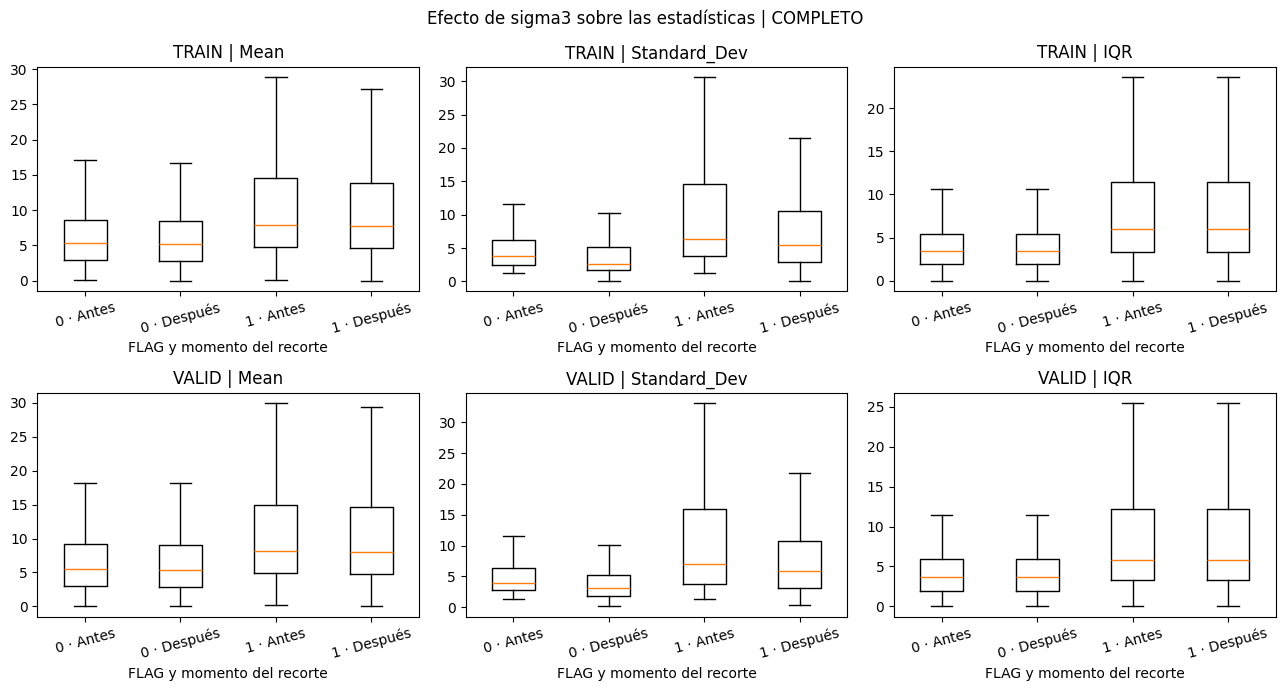

,particion,estadistica,n_consumidores,mediana_antes,mediana_despues,iqr_antes,iqr_despues,cambio_relativo
8,TRAIN,KStatvar,1000,13.52170,0.894020,66.20334,14.666370,0.99812
6,TRAIN,Kurtosis,1000,46.20277,2.102550,153.85601,5.011030,0.76628
5,TRAIN,Peak_to_Peak,1000,50.86086,20.398760,30.18932,28.712420,0.68944
4,TRAIN,Variance,1000,21.00121,15.469650,81.51462,49.786800,0.47426
7,TRAIN,kstat,1000,21.00121,15.469650,81.51462,49.786800,0.47426
25,VALID,KStatvar,1000,14.74467,1.025790,119.89076,17.998779,0.99944
23,VALID,Kurtosis,1000,32.34992,2.110560,149.28307,5.105170,0.84031
22,VALID,Peak_to_Peak,1000,50.92300,21.982040,36.08304,27.766621,0.70454
21,VALID,Variance,1000,23.31939,16.516159,94.84922,54.866261,0.56497
24,VALID,kstat,1000,23.31939,16.516159,94.84922,54.866261,0.56497


2026-11-24 21:57:45,997 | INFO | FIN: Efecto de outliers sobre las 17 estadísticas (1.8 s)


23724

In [26]:
# 8.4.1. COMPARACIÓN B: tratamiento de outliers
filas_outliers=[]
best_score=None
mejor_outlier=None
mejor_x_train=mejor_x_valid=None
mejor_feat_train=mejor_feat_valid=None
for nombre_o in tqdm(OUTLIERS,desc='ETAPA B | outliers',unit='método'):
    print('\n=== OUTLIERS:',nombre_o,'===',flush=True)
    with etapa('Transformar y extraer: '+nombre_o):
        xt,ntr=tratar_outliers(mejor_i_train,nombre_o,CFG.chunk_filas)
        xv,nva=tratar_outliers(mejor_i_valid,nombre_o,CFG.chunk_filas)
        cache=cache_features_cargar(mejor_interpolacion,nombre_o)
        if cache is not None:
            ftr,fva=cache
        else:
            ftr=extraer_17(xt,CFG.chunk_filas)
            fva=extraer_17(xv,CFG.chunk_filas)
            cache_features_guardar(mejor_interpolacion,nombre_o,ftr,fva)
    metric=referencia_rf(ftr,fva)
    filas_outliers.append({'outlier':nombre_o,'n_modificados_train':ntr,
                          'n_modificados_valid':nva,**metric})
    punt=(metric['pr_auc'],metric['recall_fraude'],metric['f1_fraude'])
    if best_score is None or punt>best_score or (punt==best_score and nombre_o<mejor_outlier):
        best_score=punt;mejor_outlier=nombre_o
        mejor_x_train,mejor_x_valid=xt,xv
        mejor_feat_train,mejor_feat_valid=ftr,fva
    if xt is not mejor_x_train:del xt,xv
    if ftr is not mejor_feat_train:del ftr,fva
    gc.collect()
comparacion_outliers=pd.DataFrame(filas_outliers)
assert mejor_outlier==elegir_mejor(comparacion_outliers,'outlier')
exportar_csv(comparacion_outliers,RUTA/'metricas'/'comparacion_outliers.csv')
display(comparacion_outliers.drop(columns=['matriz_confusion']).sort_values('pr_auc',ascending=False))
print('OUTLIER ELEGIDO:',mejor_outlier)
with etapa('Efecto de outliers sobre las 17 estadísticas'):
    comparar_estadisticas_outliers(
        [('TRAIN',mejor_i_train,mejor_feat_train,y_train),
         ('VALID',mejor_i_valid,mejor_feat_valid,y_valid)],
        mejor_outlier,
    )
del mejor_i_train,mejor_i_valid;gc.collect()

### 8.5. Comparación de las seis configuraciones

Cada extractor se ajustó una vez en TRAIN y su representación se reutilizó para SMOTE y ADASYN. La tabla siguiente reúne las seis configuraciones y sus métricas sobre VALID sin balancear. Se seleccionó la mayor PR-AUC; el par elegido se reajustó con TRAIN+VALID antes de evaluar TEST.

In [27]:
# 8.5.1. Fábrica de extractores: no ajustar dos veces para dos balanceadores

def crear_extractor(nombre):
    if nombre=='autoencoder':return ExtractorAutoencoder(CFG.semilla,CFG.modo)
    if nombre=='ica':return ExtractorICA(CFG.n_componentes_ica,CFG.semilla)
    if nombre=='pls':return ExtractorPLS(CFG.n_componentes_pls)
    raise ValueError('Extractor no reconocido: '+str(nombre))

def preparar_representaciones(nombre, Xtr_series, Xva_series, ftr, fva, ytr):
    extractor=crear_extractor(nombre)
    if nombre=='autoencoder':
        entrada_train,entrada_valid=Xtr_series,Xva_series
    else:
        entrada_train,entrada_valid=ftr,fva
    with etapa('Extractor '+nombre+' (entrenamiento solamente)'):
        extractor.fit(entrada_train,ytr if nombre=='pls' else None)
        ztr=extractor.transform(entrada_train)
        zva=extractor.transform(entrada_valid)
    print(f'{nombre}: {entrada_train.shape} -> {ztr.shape} (TRAIN), {zva.shape} (VALID)')
    return extractor,ztr,zva

Reutilizando las 17 características del tratamiento ganador (sin recálculo).


ETAPA C | 6 modelos:   0%|          | 0/6 [00:00<?, ?modelo/s]

2026-11-24 21:57:46,448 | INFO | INICIO: Extractor autoencoder (entrenamiento solamente)
2026-11-24 21:57:46,946 | INFO | INICIO: Ajustar Autoencoder en TRAIN


Autoencoder | épocas:   0%|          | 0/20 [00:00<?, ?época/s]

2026-11-24 21:58:00,392 | INFO | FIN: Ajustar Autoencoder en TRAIN (13.4 s)
2026-11-24 21:58:01,957 | INFO | FIN: Extractor autoencoder (entrenamiento solamente) (15.5 s)


autoencoder: (23728, 1034) -> (23728, 32) (TRAIN), (5932, 32) (VALID)


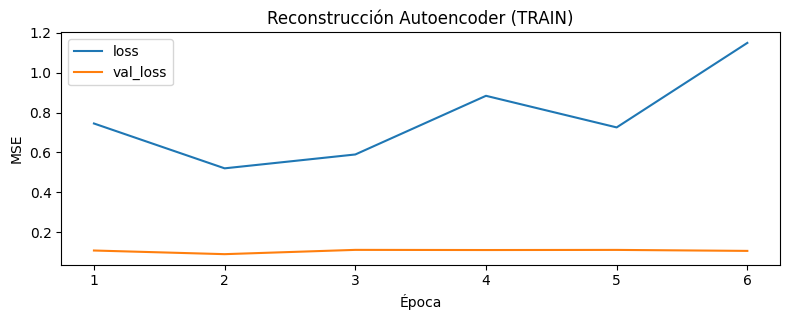


=== MODELO: autoencoder + smote + xgboost ===


2026-11-24 21:58:02,250 | INFO | INICIO: Balanceo smote sobre TRAIN


SMOTE | clases 0/1: 21704/2024 → 21704/17363 | sintéticos=15339 | proporción=0.800 | 0.072 s


2026-11-24 21:58:02,328 | INFO | FIN: Balanceo smote sobre TRAIN (0.1 s)
2026-11-24 21:58:02,328 | INFO | INICIO: Clasificador xgboost


XGBoost | árboles:   0%|          | 0/200 [00:00<?, ?árbol/s]

2026-11-24 21:58:05,482 | INFO | FIN: Clasificador xgboost (3.2 s)


... (36 outputs left out)

VALID: PR-AUC=0.24119 | recall=0.53953 | 6/6 completados


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


,id,extractor,balanceo,clasificador,segundos_entrenamiento,modo,pr_auc,roc_auc,precision_fraude,recall_fraude,f1_fraude,accuracy
0,autoencoder__smote__xgboost,autoencoder,smote,xgboost,3.16,COMPLETO,0.259516,0.715995,0.212621,0.432806,0.285156,0.814902
4,pls__smote__lightgbm,pls,smote,lightgbm,1.38,COMPLETO,0.258141,0.736958,0.186883,0.523715,0.275468,0.765003
1,autoencoder__adasyn__xgboost,autoencoder,adasyn,xgboost,6.20,COMPLETO,0.247431,0.703957,0.199825,0.452569,0.277240,0.798719
5,pls__adasyn__lightgbm,pls,adasyn,lightgbm,1.34,COMPLETO,0.241187,0.729467,0.175789,0.539526,0.265177,0.744943
2,ica__smote__random_forest,ica,smote,random_forest,28.03,COMPLETO,0.239165,0.732734,0.197068,0.478261,0.279123,0.789278
3,ica__adasyn__random_forest,ica,adasyn,random_forest,27.32,COMPLETO,0.233979,0.734391,0.190751,0.521739,0.279365,0.770398


GANADOR DE VALIDACIÓN: autoencoder__smote__xgboost


In [28]:
# 8.5.2. COMPARACIÓN C: extracción avanzada + balanceo + clasificadores
filas_modelos=[]
metric_recurso=[]
features_train,features_valid=mejor_feat_train,mejor_feat_valid
print('Reutilizando las 17 características del tratamiento ganador (sin recálculo).')
modelos_previstos=len(PARES)*len(BALANCEADORES)
_bar=tqdm(total=modelos_previstos,desc='ETAPA C | 6 modelos',unit='modelo')
completados_modelos=0

try:
    for nombre_extractor,nombre_clasificador in PARES.items():
        extractor,ztr,zva=preparar_representaciones(nombre_extractor,
                         mejor_x_train,mejor_x_valid,features_train,features_valid,y_train)
        if nombre_extractor=='autoencoder':
            hist=pd.DataFrame(extractor.historia)
            hist.to_csv(RUTA/'metricas'/'autoencoder_historial.csv',index=False)
            fig,ax=plt.subplots(figsize=(8,3.3))
            for c in ['loss','val_loss']:
                if c in hist:ax.plot(np.arange(1,len(hist)+1),hist[c],label=c)
            ax.set(xlabel='Época',ylabel='MSE',title='Reconstrucción Autoencoder (TRAIN)')
            ax.legend();fig.tight_layout();fig.savefig(RUTA/'figuras'/'autoencoder_perdida.png',dpi=140)
            plt.show();plt.close(fig)
        for bal in BALANCEADORES:
            print(f'\n=== MODELO: {nombre_extractor} + {bal} + {nombre_clasificador} ===',flush=True)
            zbal,ybal=balancear_solo_train(ztr,y_train,bal,particion='TRAIN')
            inicio=time.perf_counter()
            mod=ajustar_clasificador(nombre_clasificador,zbal,ybal,zva,y_valid)
            tiempos=time.perf_counter()-inicio
            met=metricas_binarias(y_valid,mod.predict_proba(zva)[:,1],CFG.umbral_clase)
            filas_modelos.append({'id':f'{nombre_extractor}__{bal}__{nombre_clasificador}',
                'extractor':nombre_extractor,'balanceo':bal,'clasificador':nombre_clasificador,
                'segundos_entrenamiento':round(tiempos,2),'modo':CFG.modo,**met})
            completados_modelos+=1
            print(f'VALID: PR-AUC={met["pr_auc"]:.5f} | recall={met["recall_fraude"]:.5f} | {completados_modelos}/{modelos_previstos} completados',flush=True)
            _bar.update(1)
            del mod,zbal,ybal;gc.collect()
        del extractor,ztr,zva;gc.collect()
finally:
    _bar.close()
comparacion_modelos=pd.DataFrame(filas_modelos)
assert len(comparacion_modelos)==6
mejor_id=elegir_mejor(comparacion_modelos,'id')
ganador=comparacion_modelos.set_index('id').loc[mejor_id].to_dict()
exportar_csv(comparacion_modelos,RUTA/'metricas'/'comparacion_modelos_validacion.csv')
display(comparacion_modelos.drop(columns=['matriz_confusion']).sort_values('pr_auc',ascending=False))
print('GANADOR DE VALIDACIÓN:',mejor_id)

### 8.6. Evaluación final en TEST

Después de seleccionar interpolación, tratamiento, representación, balanceador y clasificador con VALID, el flujo se reajustó desde cero con TRAIN+VALID. TEST se transformó y evaluó una sola vez, con su prevalencia original. Sus etiquetas se usaron únicamente para calcular las métricas finales.

In [29]:
# 8.6.1. Reentrenar desde cero en DEV y medir TEST sin reoptimización
import joblib
nombre_extractor=str(ganador['extractor'])
nombre_balanceo=str(ganador['balanceo'])
nombre_clasificador=str(ganador['clasificador'])
with etapa('Reentrenamiento ganador + evaluación TEST'):
    X_dev_raw=np.concatenate([X_train_raw,X_valid_raw],axis=0)
    y_dev=np.concatenate([y_train,y_valid])
    print('REENTRENAMIENTO: DEV=',len(y_dev),'| TEST=',len(y_test),flush=True)
    Xdev_i,Xtest_i=interpolacion_pares(mejor_interpolacion,X_dev_raw,X_test_raw,t_dias)
    Xdev_o,n_dev=tratar_outliers(Xdev_i,mejor_outlier,CFG.chunk_filas)
    Xtest_o,n_test=tratar_outliers(Xtest_i,mejor_outlier,CFG.chunk_filas)
    del Xdev_i,Xtest_i;gc.collect()
    if nombre_extractor=='autoencoder':
        entrada_dev,entrada_test=Xdev_o,Xtest_o
    else:
        entrada_dev=extraer_17(Xdev_o,CFG.chunk_filas)
        entrada_test=extraer_17(Xtest_o,CFG.chunk_filas)
        del Xdev_o,Xtest_o;gc.collect()
    extractor_final=crear_extractor(nombre_extractor)
    extractor_final.fit(entrada_dev,y_dev if nombre_extractor=='pls' else None)
    Zdev=extractor_final.transform(entrada_dev)
    Ztest=extractor_final.transform(entrada_test)
    Zdev_bal,ydev_bal=balancear_solo_train(Zdev,y_dev,nombre_balanceo,particion='DEV')
    model_final=ajustar_clasificador(nombre_clasificador,Zdev_bal,ydev_bal)
    proba_test=model_final.predict_proba(Ztest)[:,1]
    met_test=metricas_binarias(y_test,proba_test,CFG.umbral_clase)
    del X_dev_raw,entrada_dev,entrada_test,Zdev,Ztest,Zdev_bal,ydev_bal;gc.collect()

if set(met_test)!={'pr_auc','roc_auc','precision_fraude','recall_fraude','f1_fraude','accuracy','matriz_confusion'}:
    raise AssertionError('Métricas finales incompletas')
if sum(map(sum,met_test['matriz_confusion']))!=len(y_test):
    raise AssertionError('La matriz de confusión no corresponde a todos los consumidores TEST')
info_final={
 'ejecucion_utc':RUN_ID,'modo':CFG.modo,'semilla':CFG.semilla,'evaluaciones_test':1,
 'dataset_nombre':DATASET_PATH.name,'identidad_dataset':DATASET_KEY,'clave_pipeline':BASE_KEY,
 'n_consumidores_test':len(y_test),'n_consumidores_dev':len(y_dev),
 'seleccion_por':'PR-AUC VALID',
 'mejor_interpolacion':mejor_interpolacion,'mejor_outlier':mejor_outlier,
 'mejor_extractor':nombre_extractor,'mejor_balanceo':nombre_balanceo,
 'mejor_clasificador':nombre_clasificador,'umbral':CFG.umbral_clase,
 'metrics_valid':{k:(v.tolist() if isinstance(v,np.ndarray) else v) for k,v in ganador.items()},
 'metrics_test':met_test,'omisiones_modo_rapido':metodos_omitidos,
 'configuracion':asdict(CFG)
}
exportar_json(info_final,RUTA/'metricas'/'evaluacion_final_test.json')
# XGBoost guarda el callback de tqdm en sus parámetros; ya cumplió su función de progreso.
# Desacoplarlo evita serializar un stream no reabrible y no altera el Booster aprendido.
if nombre_clasificador=='xgboost':model_final.set_params(callbacks=[])
joblib.dump(model_final,RUTA/'modelos'/'clasificador_final.joblib')
if nombre_extractor=='autoencoder':
    extractor_final.encoder.save(RUTA/'modelos'/'encoder_final.keras')
    joblib.dump(extractor_final.scaler,RUTA/'modelos'/'escalador_encoder.joblib')
else:
    joblib.dump(extractor_final,RUTA/'modelos'/'extractor_final.joblib')
print('TEST FINAL (real) | PR-AUC:',round(met_test['pr_auc'],5),
      '| Recall fraude:',round(met_test['recall_fraude'],5),
      '| F1 fraude:',round(met_test['f1_fraude'],5))
if CFG.modo=='RAPIDO':print('ADVERTENCIA: esta es una prueba rápida, no la evidencia final.')

2026-11-24 21:59:15,982 | INFO | INICIO: Reentrenamiento ganador + evaluación TEST


REENTRENAMIENTO: DEV= 29660 | TEST= 12712
[IterativeImputer] Completing matrix with shape (29660, 1034)
[IterativeImputer] Ending imputation round 1/2, elapsed time 21.60
[IterativeImputer] Change: 1282470.5, scaled tolerance: 800.0033569335938 
[IterativeImputer] Ending imputation round 2/2, elapsed time 40.46
[IterativeImputer] Change: 1707310.75, scaled tolerance: 800.0033569335938 
Advertencia IterativeImputer: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
Advertencia IterativeImputer: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
Advertencia IterativeImputer: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.

Outliers sigma3:   0%|          | 0/58 [00:00<?, ?it/s]

Outliers sigma3:   0%|          | 0/25 [00:00<?, ?it/s]

2026-11-24 22:00:14,681 | INFO | INICIO: Ajustar Autoencoder en TRAIN


Autoencoder | épocas:   0%|          | 0/20 [00:00<?, ?época/s]

... (2 outputs left out)

2026-11-24 22:00:31,809 | INFO | FIN: Balanceo smote sobre DEV (0.1 s)
2026-11-24 22:00:31,810 | INFO | INICIO: Clasificador xgboost


XGBoost | árboles:   0%|          | 0/200 [00:00<?, ?árbol/s]

2026-11-24 22:00:35,099 | INFO | FIN: Clasificador xgboost (3.3 s)
2026-11-24 22:00:35,781 | INFO | FIN: Reentrenamiento ganador + evaluación TEST (79.8 s)


TEST FINAL (real) | PR-AUC: 0.21986 | Recall fraude: 0.38433 | F1 fraude: 0.25497


### 8.7. Figuras y artefactos

Las figuras y tablas incrustadas corresponden a la ejecución registrada en modo `COMPLETO`. Incluyen comparaciones de interpolación y valores extremos, ranking de las seis configuraciones, curva del Autoencoder y evaluación final de TEST.

2026-11-24 22:00:35,889 | INFO | INICIO: Gráficos y reportes finales


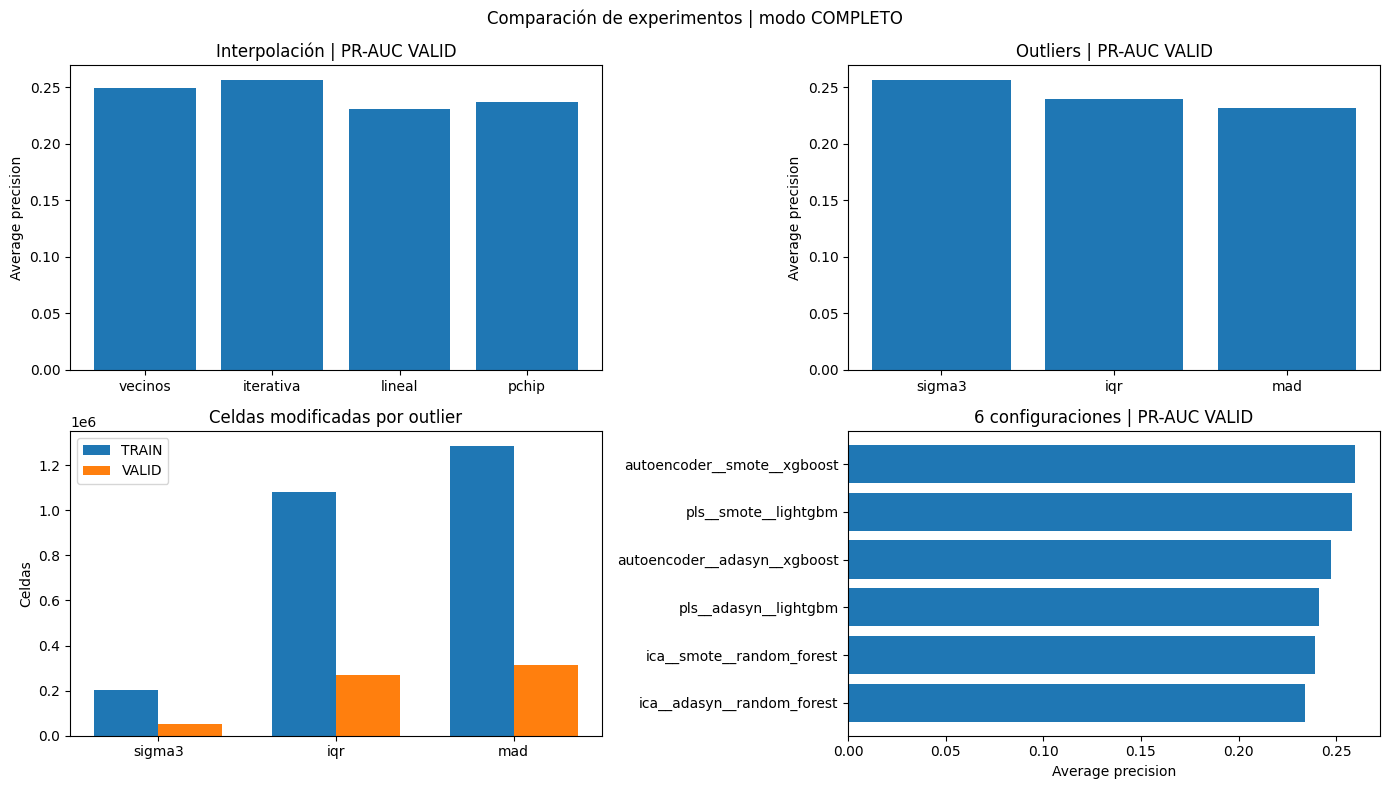

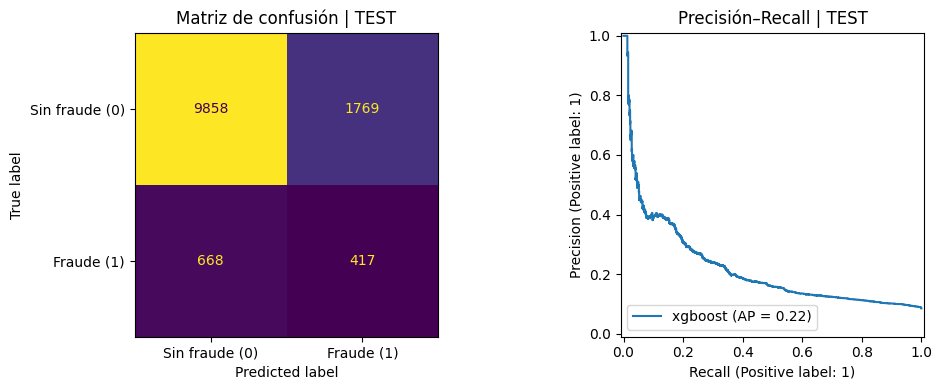

Salidas guardadas en: /content/laboratorio_electricidad


,etapa,estado,segundos,detalle
33,Ajustar Autoencoder en TRAIN,PASS,13.45,
34,Extractor autoencoder (entrenamiento solamente),PASS,15.51,
35,Balanceo smote sobre TRAIN,PASS,0.08,
36,Clasificador xgboost,PASS,3.15,
37,Balanceo adasyn sobre TRAIN,PASS,0.36,
38,Clasificador xgboost,PASS,6.19,
39,Extractor ica (entrenamiento solamente),PASS,0.19,
40,Balanceo smote sobre TRAIN,PASS,0.12,
41,Clasificador random_forest,PASS,28.03,
42,Balanceo adasyn sobre TRAIN,PASS,0.25,


2026-11-24 22:00:38,094 | INFO | FIN: Gráficos y reportes finales (2.2 s)


In [30]:
# 8.7.1. Figuras finales reproducibles
with etapa('Gráficos y reportes finales'):
    fig,axs=plt.subplots(2,2,figsize=(14,8))
    axs[0,0].bar(comparacion_interpolaciones.interpolacion,comparacion_interpolaciones.pr_auc)
    axs[0,0].set(title='Interpolación | PR-AUC VALID',ylabel='Average precision')
    axs[0,1].bar(comparacion_outliers.outlier,comparacion_outliers.pr_auc)
    axs[0,1].set(title='Outliers | PR-AUC VALID',ylabel='Average precision')
    posiciones=np.arange(len(comparacion_outliers))
    axs[1,0].bar(posiciones-.18,comparacion_outliers.n_modificados_train,width=.36,label='TRAIN')
    axs[1,0].bar(posiciones+.18,comparacion_outliers.n_modificados_valid,width=.36,label='VALID')
    axs[1,0].set_xticks(posiciones,comparacion_outliers.outlier)
    axs[1,0].set(title='Celdas modificadas por outlier',ylabel='Celdas')
    axs[1,0].legend()
    orden_modelos=comparacion_modelos.sort_values('pr_auc')
    axs[1,1].barh(orden_modelos.id,orden_modelos.pr_auc)
    axs[1,1].set(title='6 configuraciones | PR-AUC VALID',xlabel='Average precision')
    fig.suptitle('Comparación de experimentos | modo '+CFG.modo)
    fig.tight_layout();fig.savefig(RUTA/'figuras'/'comparativa_experimentos.png',dpi=150)
    plt.show();plt.close(fig)
    fig,axs=plt.subplots(1,2,figsize=(11,4))
    ConfusionMatrixDisplay(confusion_matrix=np.array(met_test['matriz_confusion']),
        display_labels=['Sin fraude (0)','Fraude (1)']).plot(ax=axs[0],colorbar=False)
    axs[0].set_title('Matriz de confusión | TEST')
    PrecisionRecallDisplay.from_predictions(y_test,proba_test,ax=axs[1],name=nombre_clasificador)
    axs[1].set_title('Precisión–Recall | TEST')
    fig.tight_layout();fig.savefig(RUTA/'figuras'/'evaluacion_final_test.png',dpi=150)
    plt.show();plt.close(fig)
    exportar_csv(pd.DataFrame(REGISTRO),RUTA/'registro'/'etapas_y_tiempos.csv')
    if metodos_omitidos:exportar_csv(pd.DataFrame(metodos_omitidos),RUTA/'registro'/'omisiones.csv')
    print('Salidas guardadas en:',RUTA)
    resumen_progreso()


## 9. Conclusiones, alcance y limitaciones

La ejecución registrada en modo `COMPLETO` comprende el análisis de calidad, cuatro interpolaciones, tres tratamientos de valores extremos, las 17 características, SMOTE y ADASYN, tres representaciones, seis configuraciones de clasificación y una evaluación final en TEST. Las conclusiones siguientes integran los resultados guardados.

In [31]:
# 9.1. Resumen automático basado exclusivamente en tablas y métricas producidas
mejor_i=comparacion_interpolaciones.sort_values(['pr_auc','recall_fraude','f1_fraude','interpolacion'],ascending=[False,False,False,True],kind='mergesort').iloc[0]
mejor_o=comparacion_outliers.sort_values(['pr_auc','recall_fraude','f1_fraude','outlier'],ascending=[False,False,False,True],kind='mergesort').iloc[0]
resumen_resultados={
 'ejecucion_utc':RUN_ID,'modo':CFG.modo,'estado':'EVIDENCIA RAPIDA / PARCIAL' if CFG.modo=='RAPIDO' else 'EXPERIMENTO COMPLETO; requiere revisión científica',
 'mejor_interpolacion_valid':{'metodo':str(mejor_i['interpolacion']),'pr_auc':float(mejor_i['pr_auc'])},
 'mejor_outlier_valid':{'metodo':str(mejor_o['outlier']),'pr_auc':float(mejor_o['pr_auc']),'celdas_train':int(mejor_o['n_modificados_train']),'celdas_valid':int(mejor_o['n_modificados_valid'])},
 'mejor_configuracion_valid':{'id':mejor_id,'pr_auc':float(ganador['pr_auc']),'recall_fraude':float(ganador['recall_fraude']),'f1_fraude':float(ganador['f1_fraude'])},
 'metricas_test':met_test,
 'diferencias_observadas':{
   'rango_pr_auc_interpolacion':float(comparacion_interpolaciones.pr_auc.max()-comparacion_interpolaciones.pr_auc.min()),
   'rango_pr_auc_outliers':float(comparacion_outliers.pr_auc.max()-comparacion_outliers.pr_auc.min()),
   'rango_pr_auc_modelos':float(comparacion_modelos.pr_auc.max()-comparacion_modelos.pr_auc.min()),
   'diferencia_pr_auc_test_vs_valid_ganador':float(met_test['pr_auc']-ganador['pr_auc'])},
 'omisiones':metodos_omitidos,
 'limitaciones':['Selección secuencial; no equivale a comparar factorialmente las 120 combinaciones.',
   'La representación de Autoencoder y las representaciones ICA/PLS usan espacios de entrada distintos.',
   'Una partición TRAIN/VALID/TEST no constituye validación cruzada.',
   'Resultados RAPIDO usan como máximo 3000 consumidores y no son evidencia final.',
   'Métricas de TEST se calculan una vez después de fijar la configuración con VALID.']}
exportar_json(resumen_resultados,RUTA/'metricas'/'resumen_resultados.json')
print('RESUMEN DE LA EJECUCIÓN',RUN_ID,'| MODO',CFG.modo)
print(f'Mejor interpolación VALID: {mejor_i.interpolacion} (PR-AUC={mejor_i.pr_auc:.4f}).')
print(f'Mejor tratamiento outliers VALID: {mejor_o.outlier} (PR-AUC={mejor_o.pr_auc:.4f}; celdas modificadas TRAIN/VALID={int(mejor_o.n_modificados_train)}/{int(mejor_o.n_modificados_valid)}).')
print(f'Mejor experimento VALID: {mejor_id} | PR-AUC={ganador["pr_auc"]:.4f}, recall={ganador["recall_fraude"]:.4f}, F1={ganador["f1_fraude"]:.4f}.')
print(f'TEST final: PR-AUC={met_test["pr_auc"]:.4f}, ROC-AUC={met_test["roc_auc"]:.4f}, accuracy={met_test["accuracy"]:.4f}, precision={met_test["precision_fraude"]:.4f}, recall={met_test["recall_fraude"]:.4f}, F1={met_test["f1_fraude"]:.4f}.')
print('Diferencia PR-AUC TEST − VALID del ganador:',f'{resumen_resultados["diferencias_observadas"]["diferencia_pr_auc_test_vs_valid_ganador"]:+.4f}')
print('Limitación: selección secuencial, no factorial; las conclusiones científicas quedan sujetas a revisar la salida COMPLETO real.')
if metodos_omitidos:print('OMISIONES:',metodos_omitidos)


RESUMEN DE LA EJECUCIÓN 20261124T215230Z | MODO COMPLETO
Mejor interpolación VALID: iterativa (PR-AUC=0.2563).
Mejor tratamiento outliers VALID: sigma3 (PR-AUC=0.2563; celdas modificadas TRAIN/VALID=201587/50000).
Mejor experimento VALID: autoencoder__smote__xgboost | PR-AUC=0.2595, recall=0.4328, F1=0.2852.
TEST final: PR-AUC=0.2199, ROC-AUC=0.6839, accuracy=0.8083, precision=0.1908, recall=0.3843, F1=0.2550.
Diferencia PR-AUC TEST − VALID del ganador: -0.0397
Limitación: selección secuencial, no factorial; las conclusiones científicas quedan sujetas a revisar la salida COMPLETO real.


### 9.2. Conclusiones

#### Calidad de los datos

El conjunto de desarrollo presentó desbalance de clases y una proporción elevada de observaciones faltantes. La tasa de ausencias fue mayor entre consumidores con `FLAG=1` que entre consumidores con `FLAG=0`; esta asociación descriptiva no establece causalidad. Las figuras de las series y del calendario complementan estos resúmenes al mostrar variación temporal en las observaciones muestreadas. Los valores faltantes y extremos justificaron comparar tratamientos antes de la clasificación.

#### Tratamientos y caracterización

La interpolación iterativa y el tratamiento 3σ obtuvieron la mayor PR-AUC en sus respectivas comparaciones de VALID. La advertencia de parada temprana del imputador y el límite de dos iteraciones restringen la interpretación de la solución iterativa. Los gráficos de características mostraron reducciones descriptivas de dispersión tras 3σ, calculadas en muestras; no se demostró que una característica individual causara una mejora predictiva.

#### Balanceo y representaciones

SMOTE alcanzó mayor PR-AUC que ADASYN en los tres pares evaluados, mientras ADASYN obtuvo mayor recall. Este compromiso depende del par y del criterio de evaluación, por lo que no implica superioridad universal. Autoencoder resumió las series diarias; ICA y PLS trabajaron sobre las 17 estadísticas, con PLS supervisado por las etiquetas de TRAIN. Las seis configuraciones comparan pares extractor-clasificador y entradas distintas.

#### Selección del modelo

Se seleccionó Autoencoder + SMOTE + XGBoost por obtener la mayor PR-AUC en VALID. PLS + SMOTE + LightGBM alcanzó un valor cercano. La diferencia observada no permite concluir significancia estadística, y la selección secuencial no equivale a una búsqueda exhaustiva.

#### Evaluación final y generalización

En TEST, el modelo obtuvo los siguientes resultados:

| Métrica | Resultado |
|---|---:|
| PR-AUC | **0,21986** |
| ROC-AUC | 0,6839 |
| Accuracy | 0,8083 |
| Precision de fraude | 0,1908 |
| Recall de fraude | 0,3843 |
| F1 de fraude | 0,25497 |

La PR-AUC descendió aproximadamente 0,0397 puntos respecto a VALID. La precision indica que una parte importante de las alertas de fraude corresponde a falsos positivos; el recall muestra que muchos fraudes reales no fueron detectados. En un conjunto desbalanceado, accuracy debe interpretarse junto con las métricas de la clase minoritaria.

#### Limitaciones

La evaluación en TEST estima el desempeño en esta división, pero no garantiza su estabilidad en otros periodos. La selección secuencial puede reflejar ajuste indirecto a VALID; las representaciones no parten de entradas idénticas; y los datos faltantes, el tratamiento de extremos y el desbalance pueden afectar los resultados. Se requiere validación adicional en otros periodos y condiciones antes de considerar una aplicación operativa.

In [32]:
# Evidencia de validación por extractor y balanceador
comparacion_balanceo = comparacion_modelos.pivot(
    index='extractor', columns='balanceo', values=['pr_auc', 'recall_fraude', 'f1_fraude'],
)
for metrica in ['pr_auc', 'recall_fraude', 'f1_fraude']:
    comparacion_balanceo[metrica, 'diferencia_adasyn_smote'] = (
        comparacion_balanceo[metrica, 'adasyn'] - comparacion_balanceo[metrica, 'smote']
    )
print(f'Métricas en VALID por extractor | modo {CFG.modo}')
if CFG.modo == 'RAPIDO':
    print('Ejecución parcial. La evidencia final requiere el modo COMPLETO.')
display(comparacion_balanceo.round(5))

Métricas en VALID por extractor | modo COMPLETO


pr_auc          recall_fraude          f1_fraude           \
balanceo      adasyn    smote        adasyn    smote    adasyn    smote   
extractor                                                                 
autoencoder  0.24743  0.25952       0.45257  0.43281   0.27724  0.28516   
ica          0.23398  0.23916       0.52174  0.47826   0.27937  0.27912   
pls          0.24119  0.25814       0.53953  0.52372   0.26518  0.27547   

                             pr_auc           recall_fraude  \
balanceo    diferencia_adasyn_smote diferencia_adasyn_smote   
extractor                                                     
autoencoder                -0.01209                 0.01976   
ica                        -0.00519                 0.04348   
pls                        -0.01695                 0.01581   

                          f1_fraude  
balanceo    diferencia_adasyn_smote  
extractor                            
autoencoder                -0.00792  
ica                         0.00024  
pls                        -0.01029